In [1]:
import sys
from pathlib import Path
assert Path(sys.prefix) == Path('/content/bike_sharing_entorno_limpio')
print('Kernel aislado confirmado:', sys.executable)

Kernel aislado confirmado: /content/bike_sharing_entorno_limpio/bin/python


# Versión reproducible - FASE4

Proyecto Bike Sharing Analytics.

Adaptación del notebook académico original.

Se utiliza el dataset local data/day.csv.
Los resultados nuevos se guardan por separado.

Instalar previamente requirements.txt.

Los algoritmos y parámetros originales se conservan.

La ejecución integral está pendiente de validación.

Notebook de origen:
notebooks/04_Preprocesamiento_Bicicletas.ipynb

In [2]:

# Localizar la raíz del repositorio.

from pathlib import Path
import sys
import hashlib

actual = Path.cwd().resolve()

candidatos = [actual, *actual.parents]

# Alternativa para Google Colab.

candidatos.append(
    Path("/content/Bike-Sharing-Analytics")
)

ROOT = next(
    (
        p for p in candidatos
        if (p / "data" / "day.csv").is_file()
        and (p / "requirements.txt").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Descarga o clona el repositorio antes de ejecutar."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils.config import DATASET, RESULTS_DIR

HASH_ESPERADO = (
    "a6bcf826782d3c0fbfdcbeead17cd0884"
    "185a0dafe8ff10cd48a874ee7ba18be"
)

assert hashlib.sha256(
    DATASET.read_bytes()
).hexdigest() == HASH_ESPERADO

print("Repositorio:", ROOT)
print("Dataset:", DATASET)
print("Integridad del dataset: OK")


Repositorio: /content/Bike-Sharing-Analytics
Dataset: /content/Bike-Sharing-Analytics/data/day.csv
Integridad del dataset: OK


# Proyecto Integrador de Ciencia de Datos
## Fase 4 – Preparación avanzada de datos y modelos de referencia

**Universidad de La Salle**

**Maestría en Inteligencia Artificial**

**Asignatura:** Ciencia de Datos

**Estudiante:** Adriana Patricia Fernández Infante

**Dataset:** Bike Sharing Dataset – UCI Machine Learning Repository

---

## 1. Introducción

La presente fase del Proyecto Integrador tiene como propósito aplicar técnicas avanzadas de preparación, limpieza y transformación de datos, garantizando la calidad de la información utilizada en los modelos de aprendizaje automático.

El estudio se desarrolla sobre el conjunto de datos Bike Sharing Dataset, que contiene información histórica sobre la demanda diaria de bicicletas, condiciones meteorológicas y variables de calendario.

## 2. Objetivo general

Implementar un proceso reproducible de preparación de datos e ingeniería de características, incorporando estrategias de prevención de fuga de información y modelos de referencia para problemas de regresión y clasificación.

## 3. Objetivos específicos

- Analizar la calidad de los datos y los mecanismos de ausencia de información.
- Justificar el tratamiento de valores faltantes y atípicos.
- Construir variables derivadas respaldadas en el conocimiento del dominio.
- Implementar estrategias de partición y análisis del desbalance de clases.
- Aplicar técnicas de codificación y escalamiento sin fuga de información.
- Implementar modelos baseline de regresión y clasificación.
- Evaluar e interpretar los resultados obtenidos.


In [3]:

# ==========================================================
# FASE 4 - CELDA 2
# Configuración del entorno y carga del dataset
# ==========================================================

# Bibliotecas para manipulación de datos
import pandas as pd
import numpy as np

# Bibliotecas para visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas para gestión de archivos
from pathlib import Path
import urllib.request
import zipfile

# Información del entorno
import sys
import sklearn

# Semilla para garantizar reproducibilidad
SEMILLA = 42
np.random.seed(SEMILLA)

# Creación de directorios
BASE = RESULTS_DIR / "reproduccion" / "fase4"
DATOS = BASE / "datos"
RESULTADOS = BASE / "resultados"

DATOS.mkdir(parents=True, exist_ok=True)
RESULTADOS.mkdir(parents=True, exist_ok=True)

# Dataset local del repositorio
ruta_dataset = DATASET

df = pd.read_csv(ruta_dataset)

# Información del entorno
print("=== ENTORNO DE EJECUCIÓN ===")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

# Información del dataset
print("\n=== DATASET ===")
print("Registros:", df.shape[0])
print("Columnas:", df.shape[1])
print("Ruta:", ruta_dataset)

display(df.head())

# Verificaciones iniciales
assert df.shape == (731, 16)
assert "cnt" in df.columns

print("\nCarga del dataset completada correctamente.")


=== ENTORNO DE EJECUCIÓN ===
Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1

=== DATASET ===
Registros: 731
Columnas: 16
Ruta: /content/Bike-Sharing-Analytics/data/day.csv


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Carga del dataset completada correctamente.



## 4. Limpieza y diagnóstico de calidad de datos

### 4.1. Exploración inicial del dataset

Antes de aplicar técnicas de imputación, transformación o eliminación de registros, se realiza un diagnóstico de calidad de los datos.

Este procedimiento permite identificar:

- Tipos de datos de cada variable.
- Valores faltantes y porcentaje de ausencia.
- Registros duplicados.
- Valores infinitos.
- Consistencia temporal de las observaciones.
- Integridad de la variable objetivo.

La variable objetivo de regresión es `cnt`, correspondiente al número total de alquileres diarios.

Se verifica que esta variable sea equivalente a la suma de los alquileres realizados por usuarios casuales (`casual`) y registrados (`registered`).

Estas dos últimas variables serán excluidas de los predictores para prevenir fuga de información.


In [4]:

# ==========================================================
# FASE 4 - CELDA 3
# Diagnóstico inicial de calidad de datos
# ==========================================================

# Crear una copia para preservar los datos originales
df_limpio = df.copy()

# Convertir la fecha al tipo datetime
df_limpio["dteday"] = pd.to_datetime(
    df_limpio["dteday"],
    errors="coerce"
)

# Ordenar cronológicamente
df_limpio = (
    df_limpio
    .sort_values("dteday")
    .reset_index(drop=True)
)

# Tabla de diagnóstico por variable
diagnostico = pd.DataFrame({
    "Tipo_dato": df_limpio.dtypes.astype(str),
    "Valores_validos": df_limpio.notna().sum(),
    "Valores_faltantes": df_limpio.isna().sum(),
    "Porcentaje_faltantes": (
        df_limpio.isna().mean() * 100
    ),
    "Valores_unicos": df_limpio.nunique()
})

print("=== DIAGNÓSTICO POR VARIABLE ===")
display(diagnostico.round(2))

# Identificar registros duplicados
duplicados = df_limpio.duplicated().sum()

# Identificar fechas duplicadas
fechas_duplicadas = (
    df_limpio["dteday"].duplicated().sum()
)

# Identificar valores infinitos
columnas_numericas = df_limpio.select_dtypes(
    include=np.number
)

infinitos = np.isinf(
    columnas_numericas.to_numpy()
).sum()

# Total de valores faltantes
total_faltantes = (
    df_limpio.isna().sum().sum()
)

# Verificar consistencia de la variable objetivo
inconsistencias_cnt = (
    df_limpio["cnt"] !=
    df_limpio["casual"] + df_limpio["registered"]
).sum()

# Verificar continuidad temporal
fechas_esperadas = pd.date_range(
    start=df_limpio["dteday"].min(),
    end=df_limpio["dteday"].max(),
    freq="D"
)

fechas_faltantes = fechas_esperadas.difference(
    df_limpio["dteday"]
)

# Resumen general
print("\n=== RESUMEN DE CALIDAD ===")
print("Total de registros:", len(df_limpio))
print("Valores faltantes:", total_faltantes)
print("Registros duplicados:", duplicados)
print("Fechas duplicadas:", fechas_duplicadas)
print("Valores infinitos:", infinitos)
print("Fechas faltantes:", len(fechas_faltantes))
print("Inconsistencias en cnt:", inconsistencias_cnt)

print("\n=== COBERTURA TEMPORAL ===")
print("Fecha inicial:", df_limpio["dteday"].min())
print("Fecha final:", df_limpio["dteday"].max())

print("\nDiagnóstico de calidad completado.")


=== DIAGNÓSTICO POR VARIABLE ===


,Tipo_dato,Valores_validos,Valores_faltantes,Porcentaje_faltantes,Valores_unicos
instant,int64,731,0,0.0,731
dteday,datetime64[ns],731,0,0.0,731
season,int64,731,0,0.0,4
yr,int64,731,0,0.0,2
mnth,int64,731,0,0.0,12
holiday,int64,731,0,0.0,2
weekday,int64,731,0,0.0,7
workingday,int64,731,0,0.0,2
weathersit,int64,731,0,0.0,3
temp,float64,731,0,0.0,499



=== RESUMEN DE CALIDAD ===
Total de registros: 731
Valores faltantes: 0
Registros duplicados: 0
Fechas duplicadas: 0
Valores infinitos: 0
Fechas faltantes: 0
Inconsistencias en cnt: 0

=== COBERTURA TEMPORAL ===
Fecha inicial: 2011-01-01 00:00:00
Fecha final: 2012-12-31 00:00:00

Diagnóstico de calidad completado.



### 4.2. Análisis de mecanismos de ausencia e imputación

Antes de seleccionar una técnica de imputación, se consideran los tres mecanismos de ausencia de datos:

- **MCAR (Missing Completely At Random):** ausencia completamente aleatoria, independiente de los valores observados y no observados.
- **MAR (Missing At Random):** ausencia explicable mediante otras variables observadas.
- **MNAR (Missing Not At Random):** ausencia relacionada con información no observada, incluso después de considerar las variables disponibles.

El diagnóstico inicial del Bike Sharing Dataset evidenció que las 16 variables contienen 731 valores válidos cada una, sin registros faltantes.

Por consiguiente, no existe evidencia empírica que permita identificar un mecanismo de ausencia MCAR, MAR o MNAR en el conjunto de datos analizado.

Se evaluaron conceptualmente las siguientes alternativas:

- Eliminación de registros incompletos.
- Imputación mediante media.
- Imputación mediante mediana.
- Imputación mediante KNNImputer.
- Imputación mediante IterativeImputer.

Ninguna de estas técnicas resulta necesaria, debido a que el dataset no presenta valores faltantes.

La decisión metodológica consiste en conservar los 731 registros originales, evitando introducir valores artificiales o eliminar información válida.

Esta decisión se fundamenta en los resultados del diagnóstico de calidad y no en una selección arbitraria de técnicas de imputación.


=== ANÁLISIS DE AUSENCIA ===
Total de celdas: 11696
Valores válidos: 11696
Valores faltantes: 0
Porcentaje de ausencia: 0.0 %

=== EVALUACIÓN DE ALTERNATIVAS ===


,Tecnica,Aplicada,Justificacion
0,Eliminación de registros,No,No existen registros incompletos
1,Media,No,No existen valores faltantes
2,Mediana,No,No existen valores faltantes
3,KNNImputer,No,No se requiere imputación
4,IterativeImputer,No,No se requiere imputación
5,Conservación de datos originales,Sí,Preserva toda la información válida


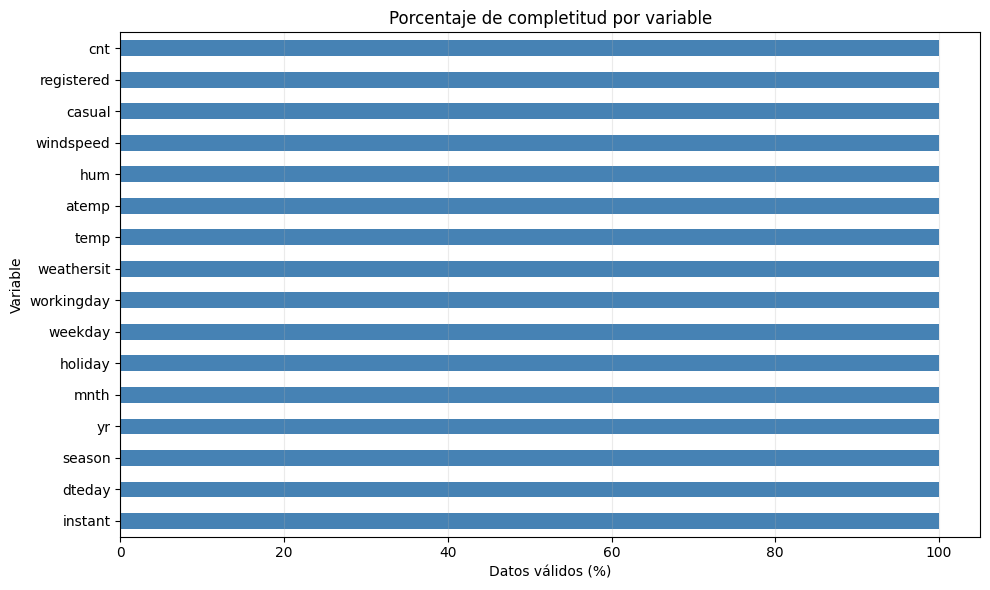


Mecanismo de ausencia: No identificable.
Imputación requerida: No.
Decisión: Conservar los datos originales.

Análisis de ausencia completado.


In [5]:

# ==========================================================
# FASE 4 - CELDA 4
# Análisis de ausencia y decisión de imputación
# ==========================================================

# Calcular cantidad total de datos
total_celdas = df_limpio.size

# Calcular valores faltantes y válidos
total_faltantes = int(
    df_limpio.isna().sum().sum()
)

total_validos = total_celdas - total_faltantes

porcentaje_ausencia = (
    total_faltantes / total_celdas
) * 100

print("=== ANÁLISIS DE AUSENCIA ===")
print("Total de celdas:", total_celdas)
print("Valores válidos:", total_validos)
print("Valores faltantes:", total_faltantes)
print(
    "Porcentaje de ausencia:",
    round(porcentaje_ausencia, 4), "%"
)

# Evaluación de alternativas de tratamiento
alternativas_imputacion = pd.DataFrame([
    {
        "Tecnica": "Eliminación de registros",
        "Aplicada": "No",
        "Justificacion": "No existen registros incompletos"
    },
    {
        "Tecnica": "Media",
        "Aplicada": "No",
        "Justificacion": "No existen valores faltantes"
    },
    {
        "Tecnica": "Mediana",
        "Aplicada": "No",
        "Justificacion": "No existen valores faltantes"
    },
    {
        "Tecnica": "KNNImputer",
        "Aplicada": "No",
        "Justificacion": "No se requiere imputación"
    },
    {
        "Tecnica": "IterativeImputer",
        "Aplicada": "No",
        "Justificacion": "No se requiere imputación"
    },
    {
        "Tecnica": "Conservación de datos originales",
        "Aplicada": "Sí",
        "Justificacion": "Preserva toda la información válida"
    }
])

print("\n=== EVALUACIÓN DE ALTERNATIVAS ===")
display(alternativas_imputacion)

# Visualizar completitud de los datos
completitud = (
    df_limpio.notna().mean() * 100
).sort_values()

plt.figure(figsize=(10, 6))

completitud.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Porcentaje de completitud por variable")
plt.xlabel("Datos válidos (%)")
plt.ylabel("Variable")
plt.xlim(0, 105)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "completitud_datos.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Decisión metodológica
if total_faltantes == 0:
    print("\nMecanismo de ausencia: No identificable.")
    print("Imputación requerida: No.")
    print("Decisión: Conservar los datos originales.")
else:
    raise ValueError(
        "Se requiere analizar el mecanismo de ausencia."
    )

# Verificaciones
assert df_limpio.shape == (731, 16)
assert total_faltantes == 0
assert porcentaje_ausencia == 0

print("\nAnálisis de ausencia completado.")



### 4.3. Detección y tratamiento de valores atípicos

Se utiliza el método del rango intercuartílico (IQR) para identificar posibles valores atípicos en las variables cuantitativas del Bike Sharing Dataset.

El rango intercuartílico se calcula como la diferencia entre el tercer y el primer cuartil.

Se consideran potencialmente atípicas las observaciones ubicadas por debajo de Q1 - 1.5 * IQR o por encima de Q3 + 1.5 * IQR.

Se analizarán las siguientes variables:

- Temperatura.
- Sensación térmica.
- Humedad.
- Velocidad del viento.
- Cantidad total de alquileres.

Se utilizarán diagramas de caja para complementar el diagnóstico estadístico.

La identificación de valores atípicos no implica su eliminación automática, debido a que pueden representar comportamientos reales de la demanda o condiciones meteorológicas excepcionales.

El análisis inicial será descriptivo. Los parámetros de cualquier transformación utilizada para el modelado se calcularán exclusivamente sobre el conjunto de entrenamiento, evitando fuga de información.


=== DIAGNÓSTICO DE VALORES ATÍPICOS ===


,Variable,Q1,Q3,IQR,Limite_inferior,Limite_superior,Outliers,Porcentaje
0,temp,0.3371,0.6554,0.3183,-0.1404,1.1329,0,0.0000
1,atemp,0.3378,0.6086,0.2708,-0.0683,1.0147,0,0.0000
2,hum,0.5200,0.7302,0.2102,0.2047,1.0455,2,0.2736
3,windspeed,0.1349,0.2332,0.0983,-0.0124,0.3806,13,1.7784
4,cnt,3152.0000,5956.0000,2804.0000,-1054.0000,10162.0000,0,0.0000


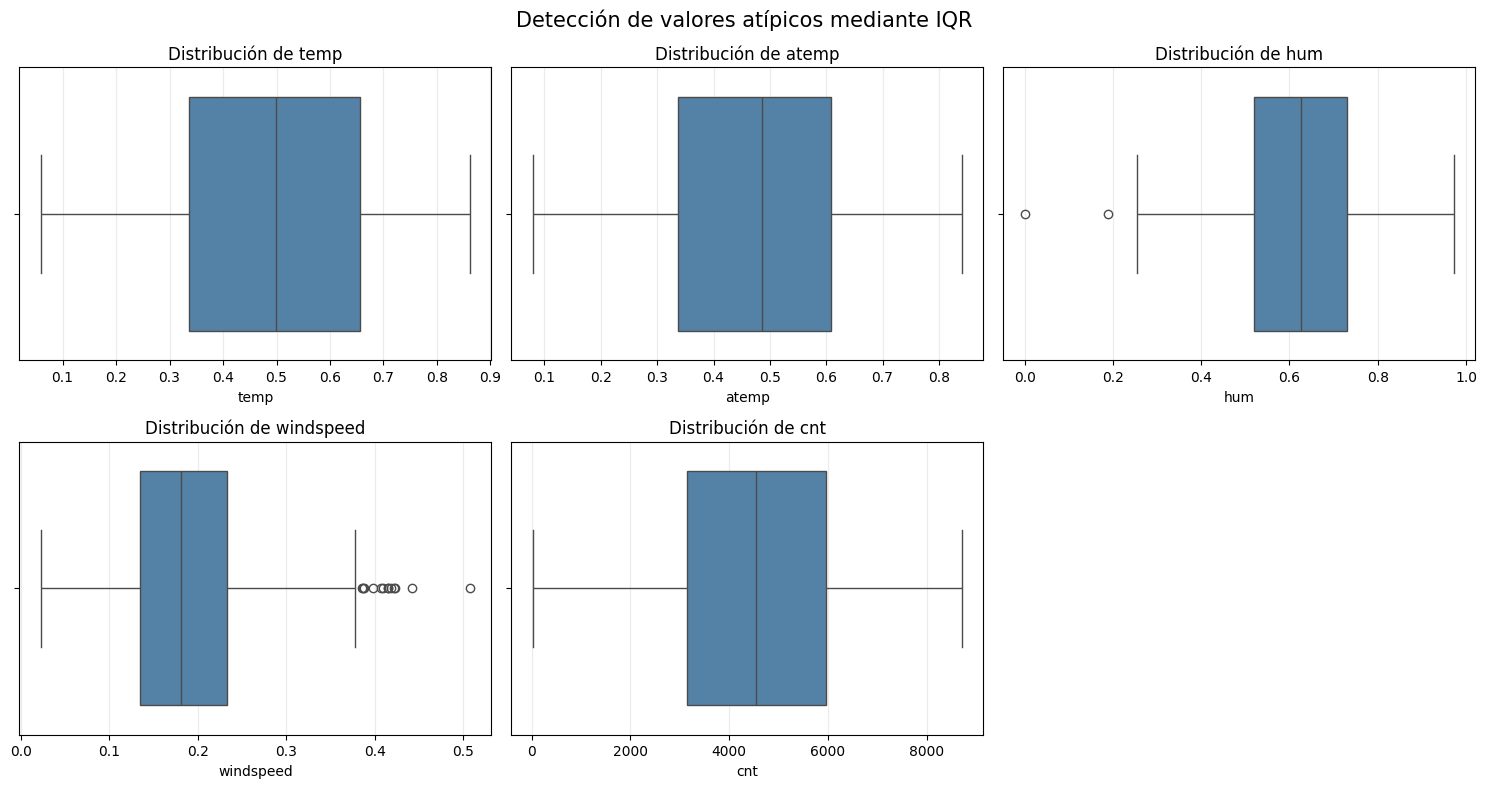


=== RESUMEN DE OUTLIERS ===
temp: 0 valores atípicos (0.00 %)
atemp: 0 valores atípicos (0.00 %)
hum: 2 valores atípicos (0.27 %)
windspeed: 13 valores atípicos (1.78 %)
cnt: 0 valores atípicos (0.00 %)

Registros conservados: 731
Gráfico guardado en: /content/Bike-Sharing-Analytics/results/reproduccion/fase4/resultados/deteccion_outliers.png
Diagnóstico de outliers completado.


In [6]:

# ==========================================================
# FASE 4 - CELDA 5
# Detección de valores atípicos mediante IQR
# ==========================================================

# Variables cuantitativas que serán analizadas
variables_outliers = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "cnt"
]

resultados_outliers = []

for variable in variables_outliers:

    # Calcular cuartiles
    q1 = df_limpio[variable].quantile(0.25)
    q3 = df_limpio[variable].quantile(0.75)

    # Rango intercuartílico
    iqr = q3 - q1

    # Límites estadísticos
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    # Identificar valores atípicos
    mascara = (
        (df_limpio[variable] < limite_inferior) |
        (df_limpio[variable] > limite_superior)
    )

    cantidad = int(mascara.sum())

    porcentaje = (
        cantidad / len(df_limpio)
    ) * 100

    resultados_outliers.append({
        "Variable": variable,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Limite_inferior": limite_inferior,
        "Limite_superior": limite_superior,
        "Outliers": cantidad,
        "Porcentaje": porcentaje
    })

# Consolidar resultados
tabla_outliers = pd.DataFrame(
    resultados_outliers
)

print("=== DIAGNÓSTICO DE VALORES ATÍPICOS ===")

display(tabla_outliers.round(4))

# Generar diagramas de caja
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8)
)

axes = axes.flatten()

for i, variable in enumerate(variables_outliers):

    sns.boxplot(
        x=df_limpio[variable],
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(
        f"Distribución de {variable}"
    )

    axes[i].grid(
        axis="x",
        alpha=0.25
    )

# Eliminar espacio gráfico sobrante
fig.delaxes(axes[5])

plt.suptitle(
    "Detección de valores atípicos mediante IQR",
    fontsize=15
)

plt.tight_layout()

# Guardar evidencia
ruta_outliers = (
    RESULTADOS / "deteccion_outliers.png"
)

plt.savefig(
    ruta_outliers,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Mostrar observaciones atípicas por variable
print("\n=== RESUMEN DE OUTLIERS ===")

for _, fila in tabla_outliers.iterrows():

    print(
        f"{fila['Variable']}: "
        f"{int(fila['Outliers'])} valores atípicos "
        f"({fila['Porcentaje']:.2f} %)"
    )

# Verificar que no se modificaron los datos
assert df_limpio.shape == (731, 16)
assert len(tabla_outliers) == 5

print("\nRegistros conservados:", len(df_limpio))
print("Gráfico guardado en:", ruta_outliers)
print("Diagnóstico de outliers completado.")



### 4.4. Selección y justificación del tratamiento de valores atípicos

El método IQR permitió identificar dos valores atípicos en la variable humedad (0.27 %) y trece en la variable velocidad del viento (1.78 %).

Las variables temperatura, sensación térmica y cantidad total de alquileres no presentaron valores atípicos según este criterio.

Se selecciona la técnica de Winsorization mediante los percentiles 1 y 99 para limitar la influencia de los valores extremos en las variables humedad y velocidad del viento.

Esta técnica permite conservar las observaciones originales sin eliminar registros completos, preservando la continuidad temporal del conjunto de datos.

La eliminación de observaciones se descarta debido al tamaño reducido del dataset y a la posibilidad de que los valores extremos representen condiciones meteorológicas reales.

Los límites de Winsorization se calcularán exclusivamente sobre el conjunto de entrenamiento y posteriormente se aplicarán a los conjuntos de validación y prueba.

Esta estrategia permite prevenir la fuga de información (Data Leakage).

Los valores originales se conservarán para efectos de trazabilidad y comparación.


In [7]:

# ==========================================================
# FASE 4 - CELDA 6
# Análisis detallado y decisión de tratamiento de outliers
# ==========================================================

variables_tratamiento = [
    "hum",
    "windspeed"
]

detalle_outliers = []

for variable in variables_tratamiento:

    # Recuperar los límites IQR del diagnóstico descriptivo
    fila = tabla_outliers.loc[
        tabla_outliers["Variable"] == variable
    ].iloc[0]

    limite_inferior = fila["Limite_inferior"]
    limite_superior = fila["Limite_superior"]

    # Identificar observaciones atípicas
    mascara = (
        (df_limpio[variable] < limite_inferior) |
        (df_limpio[variable] > limite_superior)
    )

    # Recuperar información contextual
    casos = df_limpio.loc[
        mascara,
        [
            "dteday",
            "season",
            "weathersit",
            "temp",
            "hum",
            "windspeed",
            "cnt"
        ]
    ].copy()

    casos.insert(
        0,
        "Variable_atipica",
        variable
    )

    detalle_outliers.append(casos)

# Consolidar observaciones identificadas
tabla_detalle_outliers = pd.concat(
    detalle_outliers,
    ignore_index=True
)

print("=== DETALLE DE VALORES ATÍPICOS ===")

display(tabla_detalle_outliers.round(4))

# Verificar rangos de variables normalizadas
print("\n=== RANGOS OBSERVADOS ===")

display(
    df_limpio[variables_tratamiento]
    .agg(["min", "max", "mean", "median"])
    .round(4)
)

# Documentar estrategia seleccionada
estrategia_outliers = pd.DataFrame([
    {
        "Variable": "temp",
        "Tratamiento": "Conservar"
    },
    {
        "Variable": "atemp",
        "Tratamiento": "Conservar"
    },
    {
        "Variable": "hum",
        "Tratamiento": "Winsorization P1-P99"
    },
    {
        "Variable": "windspeed",
        "Tratamiento": "Winsorization P1-P99"
    },
    {
        "Variable": "cnt",
        "Tratamiento": "Conservar"
    }
])

print("\n=== ESTRATEGIA DE TRATAMIENTO ===")

display(estrategia_outliers)

# Guardar evidencias
tabla_detalle_outliers.to_csv(
    RESULTADOS / "detalle_outliers.csv",
    index=False
)

estrategia_outliers.to_csv(
    RESULTADOS / "estrategia_outliers.csv",
    index=False
)

# Verificar que los datos originales siguen intactos
assert df_limpio.shape == (731, 16)

assert df_limpio[
    variables_tratamiento
].ge(0).all().all()

assert df_limpio[
    variables_tratamiento
].le(1).all().all()

print("\nRegistros conservados:", len(df_limpio))

print(
    "Tratamiento seleccionado:",
    "Winsorization P1-P99"
)

print(
    "Estado: pendiente de aplicación "
    "después de la partición de datos."
)

print("\nAnálisis detallado completado.")


=== DETALLE DE VALORES ATÍPICOS ===


,Variable_atipica,dteday,season,weathersit,temp,hum,windspeed,cnt
0,hum,2011-02-19,1,1,0.3992,0.1879,0.5075,1635
1,hum,2011-03-10,1,3,0.3891,0.0000,0.2619,623
2,windspeed,2011-02-14,1,1,0.4150,0.3758,0.4179,1913
3,windspeed,2011-02-19,1,1,0.3992,0.1879,0.5075,1635
4,windspeed,2011-04-04,2,1,0.5733,0.4262,0.3856,3115
5,windspeed,2011-04-05,2,2,0.4142,0.6421,0.3881,1795
6,windspeed,2011-10-20,4,1,0.4758,0.6362,0.4223,4195
7,windspeed,2012-01-18,1,1,0.3033,0.4433,0.4154,3376
8,windspeed,2012-02-12,1,1,0.1275,0.4646,0.4092,1529
9,windspeed,2012-02-25,1,1,0.2908,0.3958,0.4216,2732



=== RANGOS OBSERVADOS ===


,hum,windspeed
min,0.0000,0.0224
max,0.9725,0.5075
mean,0.6279,0.1905
median,0.6267,0.1810



=== ESTRATEGIA DE TRATAMIENTO ===


,Variable,Tratamiento
0,temp,Conservar
1,atemp,Conservar
2,hum,Winsorization P1-P99
3,windspeed,Winsorization P1-P99
4,cnt,Conservar



Registros conservados: 731
Tratamiento seleccionado: Winsorization P1-P99
Estado: pendiente de aplicación después de la partición de datos.

Análisis detallado completado.




## 5. Ingeniería y transformación de características

### 5.1. Construcción de variables derivadas

La ingeniería de características tiene como objetivo
generar nuevas representaciones de los datos que
permitan capturar patrones relevantes del dominio.

Se construyen las siguientes variables:

1. **fin_de_semana:** identifica si la observación
   corresponde a sábado o domingo, permitiendo
   representar posibles diferencias entre movilidad
   laboral y recreativa.

2. **temp_hum_interaccion:** representa la interacción
   entre temperatura y humedad, considerando que
   ambas condiciones pueden afectar conjuntamente
   la comodidad de los usuarios de bicicletas.

3. **mes_sin:** componente seno de la representación
   cíclica del mes.

4. **mes_cos:** componente coseno de la representación
   cíclica del mes.

La codificación cíclica permite representar la
continuidad de los períodos estacionales y evitar
una distancia artificial entre diciembre y enero.

Las características derivadas se construyen sin
utilizar la variable objetivo ni información futura.

La interacción temperatura-humedad se recalculará
después de aplicar Winsorization para mantener
la consistencia entre las variables transformadas.


=== INGENIERÍA DE CARACTERÍSTICAS ===
Dimensión original: (731, 16)
Dimensión transformada: (731, 20)
Variables nuevas: 4

=== EJEMPLO DE VARIABLES DERIVADAS ===


,dteday,temp,hum,mnth,fin_de_semana,temp_hum_interaccion,mes_sin,mes_cos
0,2011-01-01,0.3442,0.8058,1,1,0.2773,0.0,1.0
1,2011-01-02,0.3635,0.6961,1,1,0.2530,0.0,1.0
2,2011-01-03,0.1964,0.4373,1,0,0.0859,0.0,1.0
3,2011-01-04,0.2000,0.5904,1,0,0.1181,0.0,1.0
4,2011-01-05,0.2270,0.4370,1,0,0.0992,0.0,1.0
5,2011-01-06,0.2043,0.5183,1,0,0.1059,0.0,1.0
6,2011-01-07,0.1965,0.4987,1,0,0.0980,0.0,1.0
7,2011-01-08,0.1650,0.5358,1,1,0.0884,0.0,1.0
8,2011-01-09,0.1383,0.4342,1,1,0.0601,0.0,1.0
9,2011-01-10,0.1508,0.4829,1,0,0.0728,0.0,1.0



=== ESTADÍSTICAS DESCRIPTIVAS ===


,fin_de_semana,temp_hum_interaccion,mes_sin,mes_cos
count,731.0000,731.0000,731.0000,731.0000
mean,0.2873,0.3144,-0.0028,-0.0036
std,0.4528,0.1369,0.7073,0.7078
min,0.0000,0.0000,-1.0000,-1.0000
25%,0.0000,0.1970,-0.5000,-0.8660
50%,0.0000,0.3091,0.0000,-0.0000
75%,1.0000,0.4385,0.8660,0.5000
max,1.0000,0.5956,1.0000,1.0000



=== DISTRIBUCIÓN DE DÍAS ===


,Cantidad
fin_de_semana,
Lunes a viernes,521
Fin de semana,210


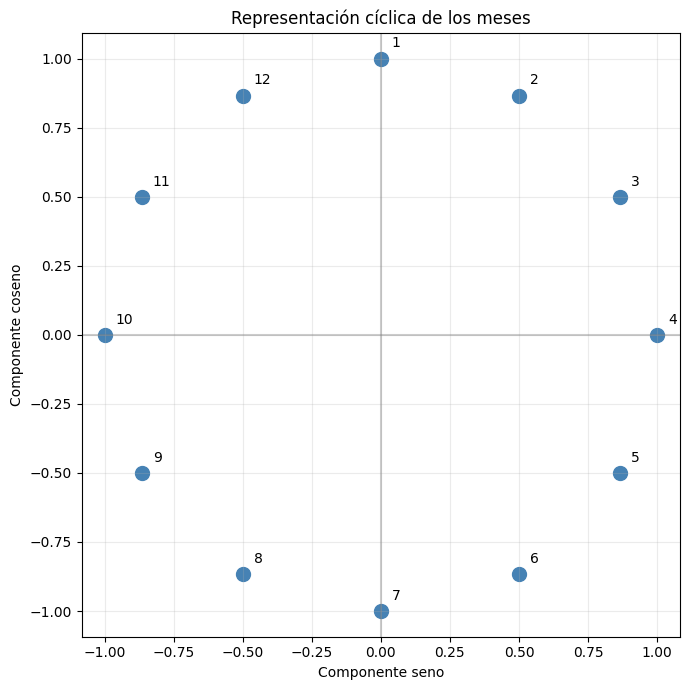


Ingeniería de características completada.


In [8]:

# ==========================================================
# FASE 4 - CELDA 7
# Ingeniería de características
# ==========================================================

def crear_caracteristicas(datos):

    # Preservar el dataframe recibido
    datos = datos.copy()

    # 1. Indicador de fin de semana
    datos["fin_de_semana"] = (
        datos["dteday"].dt.dayofweek >= 5
    ).astype(int)

    # 2. Interacción temperatura y humedad
    datos["temp_hum_interaccion"] = (
        datos["temp"] * datos["hum"]
    )

    # 3 y 4. Representación cíclica del mes
    datos["mes_sin"] = np.sin(
        2 * np.pi * (datos["mnth"] - 1) / 12
    )

    datos["mes_cos"] = np.cos(
        2 * np.pi * (datos["mnth"] - 1) / 12
    )

    return datos


# Aplicar ingeniería de características
df_features = crear_caracteristicas(df_limpio)

variables_derivadas = [
    "fin_de_semana",
    "temp_hum_interaccion",
    "mes_sin",
    "mes_cos"
]

print("=== INGENIERÍA DE CARACTERÍSTICAS ===")

print("Dimensión original:", df_limpio.shape)
print("Dimensión transformada:", df_features.shape)
print("Variables nuevas:", len(variables_derivadas))

# Visualizar las características generadas
print("\n=== EJEMPLO DE VARIABLES DERIVADAS ===")

display(
    df_features[
        ["dteday", "temp", "hum", "mnth"]
        + variables_derivadas
    ].head(10).round(4)
)

# Estadísticas descriptivas
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")

display(
    df_features[variables_derivadas]
    .describe()
    .round(4)
)

# Distribución de días
print("\n=== DISTRIBUCIÓN DE DÍAS ===")

display(
    df_features["fin_de_semana"]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Lunes a viernes",
        1: "Fin de semana"
    })
    .to_frame("Cantidad")
)

# Visualización de la codificación cíclica
meses_ciclicos = (
    df_features[
        ["mnth", "mes_sin", "mes_cos"]
    ]
    .drop_duplicates()
    .sort_values("mnth")
)

plt.figure(figsize=(7, 7))

plt.scatter(
    meses_ciclicos["mes_sin"],
    meses_ciclicos["mes_cos"],
    s=100,
    color="steelblue"
)

for _, fila in meses_ciclicos.iterrows():

    plt.annotate(
        str(int(fila["mnth"])),
        (
            fila["mes_sin"],
            fila["mes_cos"]
        ),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title("Representación cíclica de los meses")
plt.xlabel("Componente seno")
plt.ylabel("Componente coseno")
plt.axhline(0, color="gray", alpha=0.4)
plt.axvline(0, color="gray", alpha=0.4)
plt.axis("equal")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "ingenieria_caracteristicas.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Verificaciones de integridad
assert df_features.shape == (731, 20)

assert df_limpio.shape == (731, 16)

assert df_features[
    variables_derivadas
].isna().sum().sum() == 0

assert set(
    df_features["fin_de_semana"].unique()
) == {0, 1}

assert np.allclose(
    df_features["mes_sin"]**2 +
    df_features["mes_cos"]**2,
    1
)

assert df_features["cnt"].equals(
    df_limpio["cnt"]
)

print("\nIngeniería de características completada.")



## 6. Estrategia de partición de datos

### 6.1. División de entrenamiento, validación y prueba

Se establecen dos estrategias de partición de acuerdo
con la naturaleza de los problemas de aprendizaje
supervisado.

Para regresión se utiliza una división cronológica,
preservando el orden temporal de las observaciones.

Para clasificación se utiliza una división
estratificada, conservando aproximadamente la
proporción de las clases en cada subconjunto.

La distribución seleccionada es:

- Entrenamiento: 70 %.
- Validación: 15 %.
- Prueba: 15 %.

Para clasificación se conserva el umbral de 3974
alquileres diarios establecido en la Fase 3.

Clase 0: demanda inferior al umbral.
Clase 1: demanda igual o superior al umbral.

Las variables cnt, casual y registered se excluyen
de los predictores para prevenir fuga de información.

La división estratificada permite cumplir el
requerimiento académico, aunque no garantiza una
evaluación prospectiva debido a la mezcla de
observaciones de diferentes períodos temporales.

Las transformaciones estadísticas se ajustarán
exclusivamente sobre el conjunto de entrenamiento
de cada problema.


=== DISTRIBUCIÓN DE PARTICIONES ===


,Problema,Entrenamiento,Validación,Prueba
0,Regresión,511,109,111
1,Clasificación,511,110,110



=== COBERTURA TEMPORAL DE REGRESIÓN ===
Entrenamiento | Desde: 2011-01-01 | Hasta: 2012-05-25
Validación | Desde: 2012-05-26 | Hasta: 2012-09-11
Prueba | Desde: 2012-09-12 | Hasta: 2012-12-31

=== DISTRIBUCIÓN DE CLASES ===
Umbral de demanda: 3974


,Entrenamiento,Validación,Prueba
Demanda baja,193,41,42
Demanda alta,318,69,68



=== PROPORCIÓN DE CLASES (%) ===


,Entrenamiento,Validación,Prueba
Demanda baja,37.77,37.27,38.18
Demanda alta,62.23,62.73,61.82


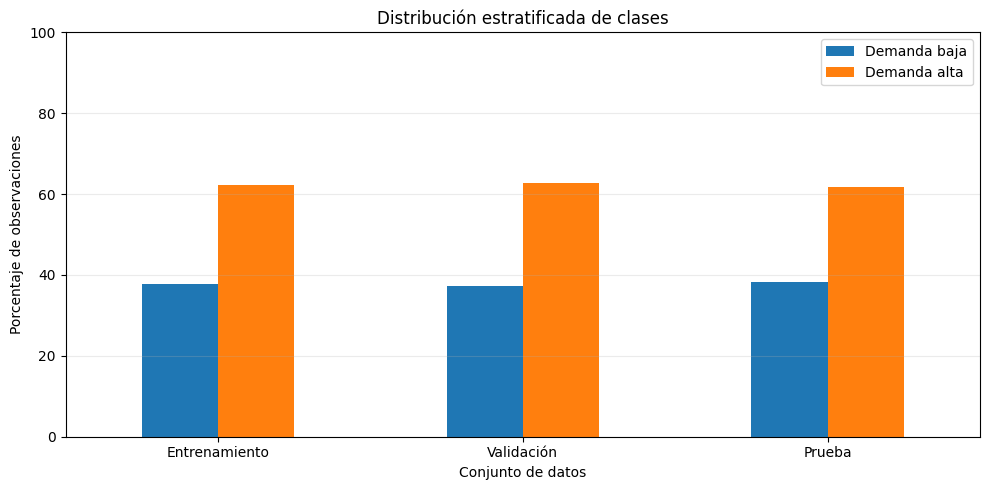


Predictores seleccionados: 14
Verificación de particiones: correcta.
Partición de datos completada.


In [9]:

# ==========================================================
# FASE 4 - CELDA 8
# Partición de entrenamiento, validación y prueba
# ==========================================================

from sklearn.model_selection import train_test_split

# ----------------------------------------------------------
# 1. Definir predictores
# ----------------------------------------------------------

numericas = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "temp_hum_interaccion",
    "mes_sin",
    "mes_cos"
]

categoricas = [
    "season",
    "yr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "fin_de_semana"
]

predictores = numericas + categoricas

X = df_features[predictores].copy()

# Variable objetivo de regresión
y_reg = df_features["cnt"].copy()

# Variable objetivo de clasificación
# Umbral previamente establecido en la Fase 3
UMBRAL_DEMANDA = 3974

y_clf = (
    y_reg >= UMBRAL_DEMANDA
).astype(int)

# ----------------------------------------------------------
# 2. Partición cronológica para regresión
# ----------------------------------------------------------

n = len(df_features)

n_train = int(n * 0.70)
n_val = int(n * 0.15)

X_train_reg = X.iloc[:n_train].copy()

X_val_reg = X.iloc[
    n_train:n_train + n_val
].copy()

X_test_reg = X.iloc[
    n_train + n_val:
].copy()

y_train_reg = y_reg.loc[X_train_reg.index]
y_val_reg = y_reg.loc[X_val_reg.index]
y_test_reg = y_reg.loc[X_test_reg.index]

# ----------------------------------------------------------
# 3. Partición estratificada para clasificación
# ----------------------------------------------------------

X_train_clf, X_temp_clf, y_train_clf, y_temp_clf = (
    train_test_split(
        X,
        y_clf,
        test_size=0.30,
        random_state=SEMILLA,
        stratify=y_clf
    )
)

# Dividir el 30 % restante en validación y prueba
X_val_clf, X_test_clf, y_val_clf, y_test_clf = (
    train_test_split(
        X_temp_clf,
        y_temp_clf,
        test_size=0.50,
        random_state=SEMILLA,
        stratify=y_temp_clf
    )
)

# ----------------------------------------------------------
# 4. Resumen de particiones
# ----------------------------------------------------------

tabla_particiones = pd.DataFrame([
    {
        "Problema": "Regresión",
        "Entrenamiento": len(X_train_reg),
        "Validación": len(X_val_reg),
        "Prueba": len(X_test_reg)
    },
    {
        "Problema": "Clasificación",
        "Entrenamiento": len(X_train_clf),
        "Validación": len(X_val_clf),
        "Prueba": len(X_test_clf)
    }
])

print("=== DISTRIBUCIÓN DE PARTICIONES ===")
display(tabla_particiones)

# ----------------------------------------------------------
# 5. Cobertura temporal de regresión
# ----------------------------------------------------------

print("\n=== COBERTURA TEMPORAL DE REGRESIÓN ===")

for nombre, conjunto in [
    ("Entrenamiento", X_train_reg),
    ("Validación", X_val_reg),
    ("Prueba", X_test_reg)
]:

    fechas = df_features.loc[
        conjunto.index, "dteday"
    ]

    print(
        nombre,
        "| Desde:", fechas.min().date(),
        "| Hasta:", fechas.max().date()
    )

# ----------------------------------------------------------
# 6. Distribución de clases
# ----------------------------------------------------------

distribucion_clases = pd.DataFrame({
    "Entrenamiento": y_train_clf.value_counts(),
    "Validación": y_val_clf.value_counts(),
    "Prueba": y_test_clf.value_counts()
}).sort_index()

distribucion_clases.index = [
    "Demanda baja",
    "Demanda alta"
]

print("\n=== DISTRIBUCIÓN DE CLASES ===")
print("Umbral de demanda:", UMBRAL_DEMANDA)

display(distribucion_clases)

# Proporciones porcentuales
proporciones_clases = (
    distribucion_clases.div(
        distribucion_clases.sum(axis=0),
        axis=1
    ) * 100
)

print("\n=== PROPORCIÓN DE CLASES (%) ===")
display(proporciones_clases.round(2))

# ----------------------------------------------------------
# 7. Visualización del balance de clases
# ----------------------------------------------------------

proporciones_clases.T.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Distribución estratificada de clases")
plt.ylabel("Porcentaje de observaciones")
plt.xlabel("Conjunto de datos")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "particion_estratificada.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 8. Verificaciones contra Data Leakage
# ----------------------------------------------------------

for train, val, test in [
    (X_train_reg, X_val_reg, X_test_reg),
    (X_train_clf, X_val_clf, X_test_clf)
]:

    assert len(train) + len(val) + len(test) == 731

    assert set(train.index).isdisjoint(val.index)
    assert set(train.index).isdisjoint(test.index)
    assert set(val.index).isdisjoint(test.index)

# Verificar orden cronológico en regresión
assert X_train_reg.index.max() < X_val_reg.index.min()

assert X_val_reg.index.max() < X_test_reg.index.min()

# Verificar presencia de ambas clases
for conjunto in [
    y_train_clf,
    y_val_clf,
    y_test_clf
]:
    assert conjunto.nunique() == 2

# Verificar exclusión de variables que generan fuga
assert not {
    "cnt", "casual", "registered"
}.intersection(predictores)

print("\nPredictores seleccionados:", len(predictores))
print("Verificación de particiones: correcta.")
print("Partición de datos completada.")



### 6.2. Análisis y tratamiento del desbalance de clases

Se analiza la distribución de la variable objetivo de
clasificación exclusivamente sobre el conjunto de
entrenamiento para determinar la necesidad de aplicar
técnicas de balanceo.

El conjunto de entrenamiento contiene:

- Demanda baja: 193 observaciones (37.77 %).
- Demanda alta: 318 observaciones (62.23 %).

El índice de desbalance (Imbalance Ratio) corresponde
al cociente entre la cantidad de observaciones de la
clase mayoritaria y la clase minoritaria.

Se obtiene un índice aproximado de 1.6477, lo cual
no evidencia un desbalance severo.

Se consideran las siguientes alternativas:

- SMOTE: generación de observaciones sintéticas
  mediante interpolación.
- ADASYN: generación adaptativa de observaciones
  sintéticas.
- Class Weight: ajuste de los pesos asignados a las
  clases durante el entrenamiento.

Se decide conservar la distribución original, debido
a que ambas clases cuentan con una representación
suficiente para establecer un modelo de referencia.

Adicionalmente, la generación de datos sintéticos
podría alterar las relaciones entre las variables
meteorológicas y de calendario.

La decisión será complementada mediante métricas
como Precision, Recall, F1 macro, Balanced Accuracy
y AUC-ROC.

En caso de requerirse técnicas de balanceo en
experimentos posteriores, estas deberán aplicarse
exclusivamente sobre el conjunto de entrenamiento.


=== DIAGNÓSTICO DE DESBALANCE ===
Clase mayoritaria: 1
Observaciones: 318
Clase minoritaria: 0
Observaciones: 193
Imbalance Ratio: 1.6477
Porcentaje clase minoritaria: 37.77 %

=== PESOS DE CLASE POTENCIALES ===


,Clase,Observaciones,Peso_balanceado
0,0,193,1.3238
1,1,318,0.8035



=== EVALUACIÓN DE ALTERNATIVAS ===


,Tecnica,Aplicada,Justificacion
0,SMOTE,No,No se evidencia desbalance severo
1,ADASYN,No,No se requiere generar datos sintéticos
2,Class Weight,No,Alternativa para experimentos posteriores
3,Distribución original,Sí,Ambas clases tienen representación suficiente


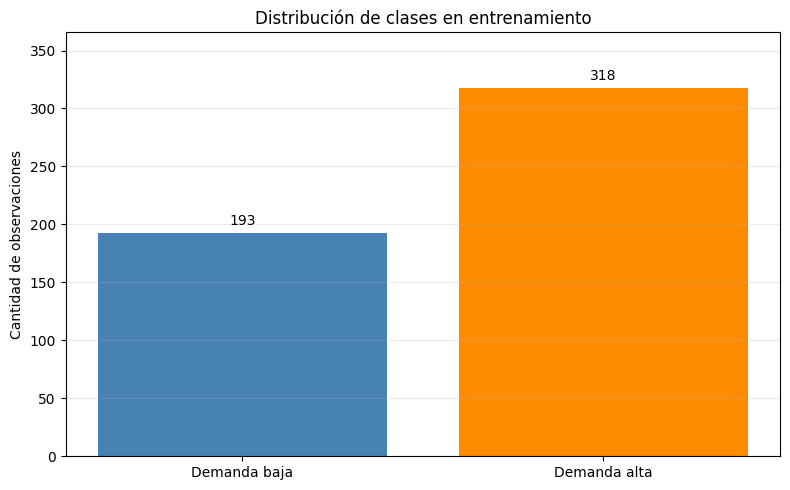


=== DECISIÓN METODOLÓGICA ===
Balanceo artificial aplicado: No
Class Weight aplicado: No
Registros conservados: 511
Datos sintéticos generados: 0

Análisis de desbalance completado.


In [10]:

# ==========================================================
# FASE 4 - CELDA 9
# Análisis y decisión de tratamiento del desbalance
# ==========================================================

from sklearn.utils.class_weight import compute_class_weight

# ----------------------------------------------------------
# 1. Distribución de clases en entrenamiento
# ----------------------------------------------------------

conteo_clases = (
    y_train_clf.value_counts()
    .sort_index()
)

clase_mayoritaria = conteo_clases.idxmax()
clase_minoritaria = conteo_clases.idxmin()

n_mayoritaria = int(conteo_clases.max())
n_minoritaria = int(conteo_clases.min())

# Calcular índice de desbalance
imbalance_ratio = n_mayoritaria / n_minoritaria

porcentaje_minoritario = (
    n_minoritaria / len(y_train_clf)
) * 100

print("=== DIAGNÓSTICO DE DESBALANCE ===")

print("Clase mayoritaria:", clase_mayoritaria)
print("Observaciones:", n_mayoritaria)

print("Clase minoritaria:", clase_minoritaria)
print("Observaciones:", n_minoritaria)

print(
    "Imbalance Ratio:",
    round(imbalance_ratio, 4)
)

print(
    "Porcentaje clase minoritaria:",
    round(porcentaje_minoritario, 2), "%"
)

# ----------------------------------------------------------
# 2. Calcular pesos de clase como alternativa
# ----------------------------------------------------------

clases = np.sort(y_train_clf.unique())

pesos = compute_class_weight(
    class_weight="balanced",
    classes=clases,
    y=y_train_clf
)

tabla_pesos = pd.DataFrame({
    "Clase": clases,
    "Observaciones": [
        conteo_clases[c] for c in clases
    ],
    "Peso_balanceado": pesos
})

print("\n=== PESOS DE CLASE POTENCIALES ===")

display(tabla_pesos.round(4))

# ----------------------------------------------------------
# 3. Evaluación de alternativas
# ----------------------------------------------------------

tabla_balanceo = pd.DataFrame([
    {
        "Tecnica": "SMOTE",
        "Aplicada": "No",
        "Justificacion":
            "No se evidencia desbalance severo"
    },
    {
        "Tecnica": "ADASYN",
        "Aplicada": "No",
        "Justificacion":
            "No se requiere generar datos sintéticos"
    },
    {
        "Tecnica": "Class Weight",
        "Aplicada": "No",
        "Justificacion":
            "Alternativa para experimentos posteriores"
    },
    {
        "Tecnica": "Distribución original",
        "Aplicada": "Sí",
        "Justificacion":
            "Ambas clases tienen representación suficiente"
    }
])

print("\n=== EVALUACIÓN DE ALTERNATIVAS ===")

display(tabla_balanceo)

# ----------------------------------------------------------
# 4. Conservar los datos originales
# ----------------------------------------------------------

X_train_clf_balanceado = X_train_clf.copy()
y_train_clf_balanceado = y_train_clf.copy()

# ----------------------------------------------------------
# 5. Visualización de la distribución
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ["Demanda baja", "Demanda alta"],
    conteo_clases.values,
    color=["steelblue", "darkorange"]
)

plt.bar_label(barras, padding=3)

plt.title("Distribución de clases en entrenamiento")
plt.ylabel("Cantidad de observaciones")
plt.ylim(0, n_mayoritaria * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "analisis_desbalance.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 6. Guardar evidencias
# ----------------------------------------------------------

tabla_balanceo.to_csv(
    RESULTADOS / "estrategia_balanceo.csv",
    index=False
)

tabla_pesos.to_csv(
    RESULTADOS / "pesos_clases.csv",
    index=False
)

# ----------------------------------------------------------
# 7. Verificaciones
# ----------------------------------------------------------

assert len(X_train_clf_balanceado) == 511

assert y_train_clf_balanceado.equals(
    y_train_clf
)

assert X_train_clf_balanceado.equals(
    X_train_clf
)

assert y_train_clf_balanceado.nunique() == 2

print("\n=== DECISIÓN METODOLÓGICA ===")
print("Balanceo artificial aplicado: No")
print("Class Weight aplicado: No")
print("Registros conservados:", len(X_train_clf))
print("Datos sintéticos generados: 0")

print("\nAnálisis de desbalance completado.")



## 7. Transformación y preprocesamiento de datos

### 7.1. Aplicación de Winsorization

Se aplica la técnica de Winsorization mediante los
percentiles 1 y 99 sobre las variables humedad
(hum) y velocidad del viento (windspeed).

El objetivo es limitar la influencia de los valores
extremos sin eliminar observaciones.

Debido a que los problemas de regresión y clasificación
utilizan estrategias de partición diferentes, los
límites de Winsorization se calculan independientemente
sobre cada conjunto de entrenamiento.

Los límites obtenidos se aplican posteriormente
a los conjuntos de entrenamiento, validación y prueba,
sin recalcular los percentiles.

Después del tratamiento se recalcula la variable
derivada temp_hum_interaccion para garantizar
su consistencia con la humedad transformada.

La variable objetivo no se modifica.

Finalmente, se cuantifica la cantidad de valores
modificados y se comparan gráficamente las
distribuciones antes y después del tratamiento.

Este procedimiento permite prevenir la fuga de
información durante el ajuste de la transformación.


=== LÍMITES DE WINSORIZATION ===


,Problema,Variable,P1,P99
0,Regresión,hum,0.302457,0.938608
1,Regresión,windspeed,0.050663,0.415366
2,Clasificación,hum,0.311560,0.938608
3,Clasificación,windspeed,0.047835,0.406412



=== VALORES MODIFICADOS ===


,Problema,Conjunto,Variable,Registros,Valores_modificados,Porcentaje
0,Regresión,Entrenamiento,hum,511,12,2.3483
1,Regresión,Entrenamiento,windspeed,511,12,2.3483
2,Regresión,Validación,hum,109,0,0.0000
3,Regresión,Validación,windspeed,109,0,0.0000
4,Regresión,Prueba,hum,111,0,0.0000
5,Regresión,Prueba,windspeed,111,1,0.9009
6,Clasificación,Entrenamiento,hum,511,12,2.3483
7,Clasificación,Entrenamiento,windspeed,511,12,2.3483
8,Clasificación,Validación,hum,110,1,0.9091
9,Clasificación,Validación,windspeed,110,0,0.0000


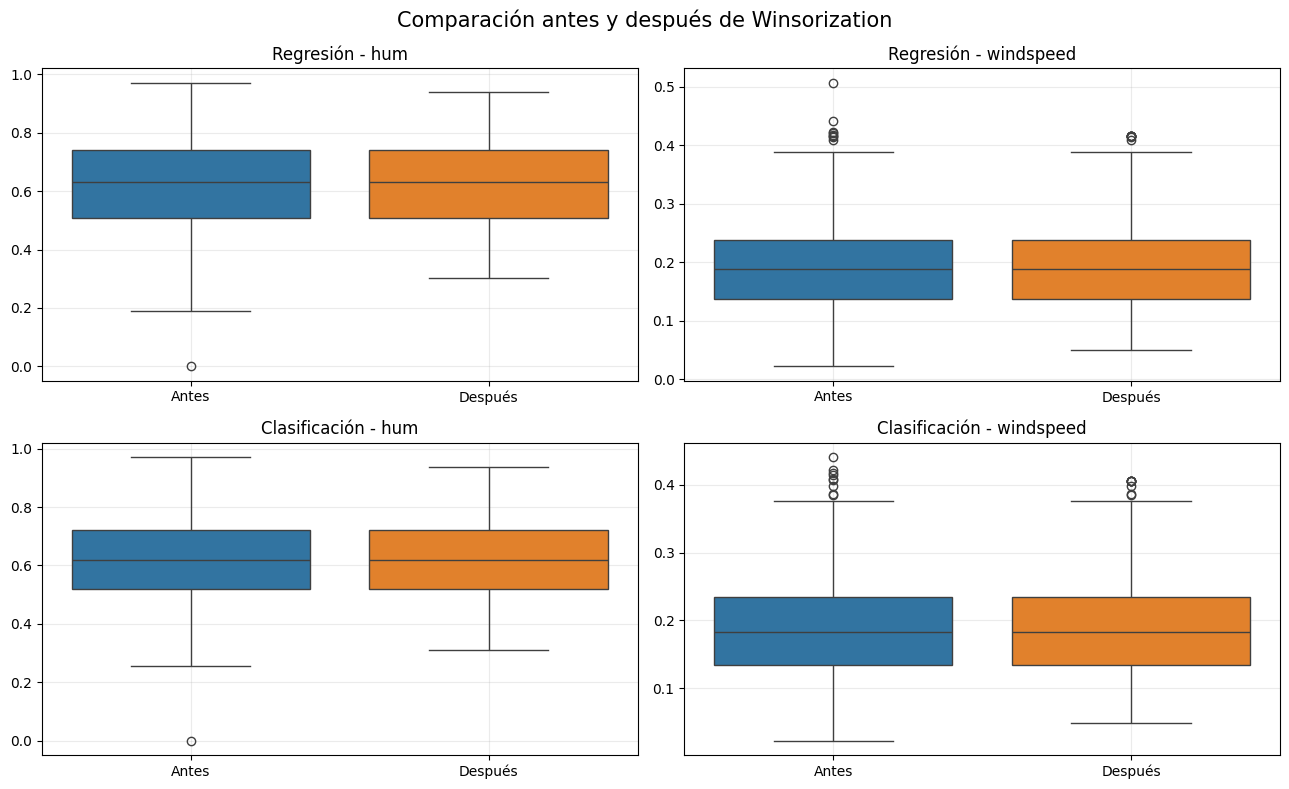


=== VERIFICACIÓN FINAL ===
Registros eliminados: 0
Variables objetivo modificadas: 0
Valores faltantes generados: 0
Límites calculados solo en entrenamiento: Sí
Winsorization completada correctamente.


In [11]:

# ==========================================================
# FASE 4 - CELDA 10
# Winsorization sin fuga de información
# ==========================================================

variables_winsor = ["hum", "windspeed"]

# ----------------------------------------------------------
# 1. Función para calcular límites en entrenamiento
# ----------------------------------------------------------

def calcular_limites_winsor(X_train):

    limites = {}

    for variable in variables_winsor:

        limites[variable] = {
            "P1": X_train[variable].quantile(0.01),
            "P99": X_train[variable].quantile(0.99)
        }

    return limites


# ----------------------------------------------------------
# 2. Función para aplicar Winsorization
# ----------------------------------------------------------

def aplicar_winsor(X, limites):

    datos = X.copy()

    for variable, valores in limites.items():

        datos[variable] = datos[variable].clip(
            lower=valores["P1"],
            upper=valores["P99"]
        )

    # Recalcular la interacción temperatura-humedad
    datos["temp_hum_interaccion"] = (
        datos["temp"] * datos["hum"]
    )

    return datos


# ----------------------------------------------------------
# 3. Calcular límites independientes
# ----------------------------------------------------------

limites_reg = calcular_limites_winsor(
    X_train_reg
)

limites_clf = calcular_limites_winsor(
    X_train_clf
)

tabla_limites = pd.DataFrame([
    {
        "Problema": problema,
        "Variable": variable,
        "P1": valores["P1"],
        "P99": valores["P99"]
    }
    for problema, limites in [
        ("Regresión", limites_reg),
        ("Clasificación", limites_clf)
    ]
    for variable, valores in limites.items()
])

print("=== LÍMITES DE WINSORIZATION ===")

display(tabla_limites.round(6))


# ----------------------------------------------------------
# 4. Aplicar tratamiento para regresión
# ----------------------------------------------------------

X_train_reg_w = aplicar_winsor(
    X_train_reg, limites_reg
)

X_val_reg_w = aplicar_winsor(
    X_val_reg, limites_reg
)

X_test_reg_w = aplicar_winsor(
    X_test_reg, limites_reg
)


# ----------------------------------------------------------
# 5. Aplicar tratamiento para clasificación
# ----------------------------------------------------------

X_train_clf_w = aplicar_winsor(
    X_train_clf, limites_clf
)

X_val_clf_w = aplicar_winsor(
    X_val_clf, limites_clf
)

X_test_clf_w = aplicar_winsor(
    X_test_clf, limites_clf
)


# ----------------------------------------------------------
# 6. Cuantificar valores modificados
# ----------------------------------------------------------

comparaciones = [
    ("Regresión", "Entrenamiento",
     X_train_reg, X_train_reg_w),

    ("Regresión", "Validación",
     X_val_reg, X_val_reg_w),

    ("Regresión", "Prueba",
     X_test_reg, X_test_reg_w),

    ("Clasificación", "Entrenamiento",
     X_train_clf, X_train_clf_w),

    ("Clasificación", "Validación",
     X_val_clf, X_val_clf_w),

    ("Clasificación", "Prueba",
     X_test_clf, X_test_clf_w)
]

resultados_winsor = []

for problema, conjunto, original, tratado in comparaciones:

    for variable in variables_winsor:

        modificados = int(
            (original[variable] != tratado[variable]).sum()
        )

        resultados_winsor.append({
            "Problema": problema,
            "Conjunto": conjunto,
            "Variable": variable,
            "Registros": len(original),
            "Valores_modificados": modificados,
            "Porcentaje": modificados / len(original) * 100
        })

tabla_winsor = pd.DataFrame(resultados_winsor)

print("\n=== VALORES MODIFICADOS ===")

display(tabla_winsor.round(4))


# ----------------------------------------------------------
# 7. Visualización antes y después
# ----------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 8)
)

for i, (problema, original, tratado) in enumerate([
    ("Regresión", X_train_reg, X_train_reg_w),
    ("Clasificación", X_train_clf, X_train_clf_w)
]):

    for j, variable in enumerate(variables_winsor):

        datos_grafico = pd.DataFrame({
            "Antes": original[variable],
            "Después": tratado[variable]
        })

        sns.boxplot(
            data=datos_grafico,
            ax=axes[i, j]
        )

        axes[i, j].set_title(
            f"{problema} - {variable}"
        )

        axes[i, j].grid(alpha=0.25)

plt.suptitle(
    "Comparación antes y después de Winsorization",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    RESULTADOS / "comparacion_winsorization.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ----------------------------------------------------------
# 8. Verificaciones de integridad
# ----------------------------------------------------------

for problema, conjunto, original, tratado in comparaciones:

    # Conservar dimensiones e índices
    assert original.shape == tratado.shape
    assert original.index.equals(tratado.index)

    # Verificar ausencia de valores faltantes
    assert tratado.isna().sum().sum() == 0

    # Verificar consistencia de variable derivada
    assert np.allclose(
        tratado["temp_hum_interaccion"],
        tratado["temp"] * tratado["hum"]
    )

    limites = (
        limites_reg
        if problema == "Regresión"
        else limites_clf
    )

    # Verificar límites aplicados
    for variable in variables_winsor:

        assert tratado[variable].ge(
            limites[variable]["P1"]
        ).all()

        assert tratado[variable].le(
            limites[variable]["P99"]
        ).all()

    # Verificar que las demás variables no cambiaron
    columnas_intactas = [
        c for c in original.columns
        if c not in variables_winsor
        + ["temp_hum_interaccion"]
    ]

    assert original[columnas_intactas].equals(
        tratado[columnas_intactas]
    )


# ----------------------------------------------------------
# 9. Guardar evidencias
# ----------------------------------------------------------

tabla_limites.to_csv(
    RESULTADOS / "limites_winsorization.csv",
    index=False
)

tabla_winsor.to_csv(
    RESULTADOS / "resultados_winsorization.csv",
    index=False
)

print("\n=== VERIFICACIÓN FINAL ===")
print("Registros eliminados: 0")
print("Variables objetivo modificadas: 0")
print("Valores faltantes generados: 0")
print("Límites calculados solo en entrenamiento: Sí")
print("Winsorization completada correctamente.")



### 7.2. Codificación de variables categóricas

Se utiliza la técnica One-Hot Encoding para transformar
las variables categóricas en representaciones binarias.

Esta técnica evita introducir relaciones ordinales
artificiales entre categorías cuyos códigos numéricos
representan etiquetas y no magnitudes.

Las variables seleccionadas son season, yr, holiday,
weekday, workingday, weathersit y fin_de_semana.

Se implementan dos codificadores independientes,
uno para regresión y otro para clasificación.

Cada codificador se ajusta exclusivamente sobre su
respectivo conjunto de entrenamiento mediante fit.

Posteriormente, se aplica transform sobre los conjuntos
de entrenamiento, validación y prueba, conservando
la misma estructura de características.

Se utiliza handle_unknown="ignore" para gestionar
categorías no observadas durante el entrenamiento.

Este procedimiento previene la fuga de información
durante el aprendizaje de las categorías.

Se conservan todas las categorías para facilitar
la trazabilidad de la transformación. La posible
redundancia entre columnas deberá considerarse
durante la interpretación de los modelos lineales.


In [12]:

# ==========================================================
# FASE 4 - CELDA 11
# Codificación categórica sin Data Leakage
# ==========================================================

from sklearn.preprocessing import OneHotEncoder

# ----------------------------------------------------------
# 1. Crear codificadores independientes
# ----------------------------------------------------------

encoder_reg = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder_clf = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# ----------------------------------------------------------
# 2. Ajustar exclusivamente sobre entrenamiento
# ----------------------------------------------------------

encoder_reg.fit(
    X_train_reg_w[categoricas]
)

encoder_clf.fit(
    X_train_clf_w[categoricas]
)

# ----------------------------------------------------------
# 3. Función para transformar variables categóricas
# ----------------------------------------------------------

def codificar_categoricas(datos, encoder):

    matriz = encoder.transform(
        datos[categoricas]
    )

    nombres = encoder.get_feature_names_out(
        categoricas
    )

    return pd.DataFrame(
        matriz,
        columns=nombres,
        index=datos.index
    )

# ----------------------------------------------------------
# 4. Codificación para regresión
# ----------------------------------------------------------

X_train_reg_cat = codificar_categoricas(
    X_train_reg_w, encoder_reg
)

X_val_reg_cat = codificar_categoricas(
    X_val_reg_w, encoder_reg
)

X_test_reg_cat = codificar_categoricas(
    X_test_reg_w, encoder_reg
)

# ----------------------------------------------------------
# 5. Codificación para clasificación
# ----------------------------------------------------------

X_train_clf_cat = codificar_categoricas(
    X_train_clf_w, encoder_clf
)

X_val_clf_cat = codificar_categoricas(
    X_val_clf_w, encoder_clf
)

X_test_clf_cat = codificar_categoricas(
    X_test_clf_w, encoder_clf
)

# ----------------------------------------------------------
# 6. Categorías aprendidas en entrenamiento
# ----------------------------------------------------------

tabla_categorias = pd.DataFrame([
    {
        "Problema": problema,
        "Variable": variable,
        "Categorias": list(categorias),
        "Columnas_generadas": len(categorias)
    }
    for problema, encoder in [
        ("Regresión", encoder_reg),
        ("Clasificación", encoder_clf)
    ]
    for variable, categorias in zip(
        categoricas, encoder.categories_
    )
])

print("=== CATEGORÍAS APRENDIDAS ===")

display(tabla_categorias)

# ----------------------------------------------------------
# 7. Dimensiones de los conjuntos codificados
# ----------------------------------------------------------

conjuntos_codificados = [
    ("Regresión", "Entrenamiento",
     X_train_reg_w, X_train_reg_cat),

    ("Regresión", "Validación",
     X_val_reg_w, X_val_reg_cat),

    ("Regresión", "Prueba",
     X_test_reg_w, X_test_reg_cat),

    ("Clasificación", "Entrenamiento",
     X_train_clf_w, X_train_clf_cat),

    ("Clasificación", "Validación",
     X_val_clf_w, X_val_clf_cat),

    ("Clasificación", "Prueba",
     X_test_clf_w, X_test_clf_cat)
]

tabla_codificacion = pd.DataFrame([
    {
        "Problema": problema,
        "Conjunto": conjunto,
        "Registros": len(codificado),
        "Variables_originales": len(categoricas),
        "Columnas_codificadas": codificado.shape[1]
    }
    for problema, conjunto, original, codificado
    in conjuntos_codificados
])

print("\n=== DIMENSIONES DESPUÉS DE CODIFICAR ===")

display(tabla_codificacion)

# ----------------------------------------------------------
# 8. Ejemplo de transformación
# ----------------------------------------------------------

print("\n=== EJEMPLO DE CODIFICACIÓN ===")

display(
    X_train_reg_cat.head().astype(int)
)

# ----------------------------------------------------------
# 9. Verificaciones de integridad
# ----------------------------------------------------------

for problema, conjunto, original, codificado in (
    conjuntos_codificados
):

    assert len(original) == len(codificado)

    assert original.index.equals(
        codificado.index
    )

    assert codificado.isna().sum().sum() == 0

    assert np.isin(
        codificado.to_numpy(),
        [0, 1]
    ).all()

# Verificar consistencia de columnas en regresión
assert X_train_reg_cat.columns.equals(
    X_val_reg_cat.columns
)

assert X_train_reg_cat.columns.equals(
    X_test_reg_cat.columns
)

# Verificar consistencia de columnas en clasificación
assert X_train_clf_cat.columns.equals(
    X_val_clf_cat.columns
)

assert X_train_clf_cat.columns.equals(
    X_test_clf_cat.columns
)

# ----------------------------------------------------------
# 10. Verificar categorías desconocidas
# ----------------------------------------------------------

resultados_desconocidas = []

for problema, conjunto, original, codificado in (
    conjuntos_codificados
):

    encoder = (
        encoder_reg
        if problema == "Regresión"
        else encoder_clf
    )

    for variable, categorias in zip(
        categoricas, encoder.categories_
    ):

        cantidad = int(
            (~original[variable].isin(categorias)).sum()
        )

        resultados_desconocidas.append({
            "Problema": problema,
            "Conjunto": conjunto,
            "Variable": variable,
            "Categorias_desconocidas": cantidad
        })

tabla_desconocidas = pd.DataFrame(
    resultados_desconocidas
)

print("\n=== CATEGORÍAS DESCONOCIDAS ===")

display(
    tabla_desconocidas.groupby(
        ["Problema", "Conjunto"]
    )["Categorias_desconocidas"]
    .sum()
    .reset_index()
)

# ----------------------------------------------------------
# 11. Guardar evidencias
# ----------------------------------------------------------

tabla_categorias.to_csv(
    RESULTADOS / "categorias_aprendidas.csv",
    index=False
)

tabla_codificacion.to_csv(
    RESULTADOS / "resultados_codificacion.csv",
    index=False
)

tabla_desconocidas.to_csv(
    RESULTADOS / "categorias_desconocidas.csv",
    index=False
)

print("\n=== VERIFICACIÓN FINAL ===")

print("Codificadores independientes: 2")
print("Ajuste exclusivo en entrenamiento: Sí")
print("Registros eliminados: 0")
print("Valores faltantes generados: 0")
print("Codificación One-Hot completada.")


=== CATEGORÍAS APRENDIDAS ===


,Problema,Variable,Categorias,Columnas_generadas
0,Regresión,season,"[1, 2, 3, 4]",4
1,Regresión,yr,"[0, 1]",2
2,Regresión,holiday,"[0, 1]",2
3,Regresión,weekday,"[0, 1, 2, 3, 4, 5, 6]",7
4,Regresión,workingday,"[0, 1]",2
5,Regresión,weathersit,"[1, 2, 3]",3
6,Regresión,fin_de_semana,"[0, 1]",2
7,Clasificación,season,"[1, 2, 3, 4]",4
8,Clasificación,yr,"[0, 1]",2
9,Clasificación,holiday,"[0, 1]",2



=== DIMENSIONES DESPUÉS DE CODIFICAR ===


,Problema,Conjunto,Registros,Variables_originales,Columnas_codificadas
0,Regresión,Entrenamiento,511,7,22
1,Regresión,Validación,109,7,22
2,Regresión,Prueba,111,7,22
3,Clasificación,Entrenamiento,511,7,22
4,Clasificación,Validación,110,7,22
5,Clasificación,Prueba,110,7,22



=== EJEMPLO DE CODIFICACIÓN ===


,season_1,season_2,season_3,season_4,yr_0,yr_1,holiday_0,holiday_1,weekday_0,weekday_1,...,weekday_4,weekday_5,weekday_6,workingday_0,workingday_1,weathersit_1,weathersit_2,weathersit_3,fin_de_semana_0,fin_de_semana_1
0,1,0,0,0,1,0,1,0,0,0,...,0,0,1,1,0,0,1,0,0,1
1,1,0,0,0,1,0,1,0,1,0,...,0,0,0,1,0,0,1,0,0,1
2,1,0,0,0,1,0,1,0,0,1,...,0,0,0,0,1,1,0,0,1,0
3,1,0,0,0,1,0,1,0,0,0,...,0,0,0,0,1,1,0,0,1,0
4,1,0,0,0,1,0,1,0,0,0,...,0,0,0,0,1,1,0,0,1,0



=== CATEGORÍAS DESCONOCIDAS ===


,Problema,Conjunto,Categorias_desconocidas
0,Clasificación,Entrenamiento,0
1,Clasificación,Prueba,0
2,Clasificación,Validación,0
3,Regresión,Entrenamiento,0
4,Regresión,Prueba,0
5,Regresión,Validación,0



=== VERIFICACIÓN FINAL ===
Codificadores independientes: 2
Ajuste exclusivo en entrenamiento: Sí
Registros eliminados: 0
Valores faltantes generados: 0
Codificación One-Hot completada.



### 7.3. Estandarización de variables numéricas

Se utiliza StandardScaler para transformar las siete
variables numéricas seleccionadas.

La estandarización consiste en restar la media y
dividir por la desviación estándar de cada variable.

Esta transformación permite obtener características
con media aproximadamente igual a cero y desviación
estándar igual a uno en el conjunto de entrenamiento.

Se implementan dos escaladores independientes:

- StandardScaler para regresión.
- StandardScaler para clasificación.

Cada escalador se ajusta exclusivamente sobre su
respectivo conjunto de entrenamiento.

Los conjuntos de validación y prueba se transforman
utilizando los parámetros aprendidos durante el
entrenamiento, evitando fuga de información.

Las variables categóricas previamente codificadas
mediante One-Hot Encoding conservan sus valores
binarios originales.

Finalmente, se concatenan las siete variables
numéricas estandarizadas y las 22 columnas binarias,
obteniendo 29 características predictoras.

La variable objetivo permanece sin modificaciones.


=== PARÁMETROS DE STANDARD SCALER ===


,Problema,Variable,Media_entrenamiento,Desviacion_entrenamiento
0,Regresión,temp,0.466014,0.178548
1,Regresión,atemp,0.449079,0.160025
2,Regresión,hum,0.628017,0.149014
3,Regresión,windspeed,0.196166,0.077337
4,Regresión,temp_hum_interaccion,0.297664,0.138712
5,Regresión,mes_sin,0.179510,0.692826
6,Regresión,mes_cos,0.112295,0.689318
7,Clasificación,temp,0.500098,0.186938
8,Clasificación,atemp,0.479372,0.166080
9,Clasificación,hum,0.625915,0.138136



=== VERIFICACIÓN DE ESTANDARIZACIÓN ===


,Problema,Variable,Media_transformada,Desviacion_transformada
0,Regresión,temp,-0.0,1.0
1,Regresión,atemp,-0.0,1.0
2,Regresión,hum,-0.0,1.0
3,Regresión,windspeed,0.0,1.0
4,Regresión,temp_hum_interaccion,-0.0,1.0
5,Regresión,mes_sin,0.0,1.0
6,Regresión,mes_cos,0.0,1.0
7,Clasificación,temp,-0.0,1.0
8,Clasificación,atemp,0.0,1.0
9,Clasificación,hum,0.0,1.0



=== MATRICES FINALES ===


,Problema,Conjunto,Registros,Caracteristicas,Valores_faltantes
0,Regresión,Entrenamiento,511,29,0
1,Regresión,Validación,109,29,0
2,Regresión,Prueba,111,29,0
3,Clasificación,Entrenamiento,511,29,0
4,Clasificación,Validación,110,29,0
5,Clasificación,Prueba,110,29,0



=== EJEMPLO DE MATRIZ FINAL ===


,temp,atemp,hum,windspeed,temp_hum_interaccion,mes_sin,mes_cos,season_1,season_2,season_3,...,weekday_4,weekday_5,weekday_6,workingday_0,workingday_1,weathersit_1,weathersit_2,weathersit_3,fin_de_semana_0,fin_de_semana_1
0,-0.6824,-0.5340,1.1933,-0.4619,-0.1465,-0.2591,1.2878,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,-0.5743,-0.5958,0.4568,0.6772,-0.3219,-0.2591,1.2878,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
2,-1.5102,-1.6227,-1.2800,0.6742,-1.5269,-0.2591,1.2878,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
3,-1.4899,-1.4808,-0.2522,-0.4638,-1.2946,-0.2591,1.2878,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
4,-1.3389,-1.3736,-1.2822,-0.1198,-1.4310,-0.2591,1.2878,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


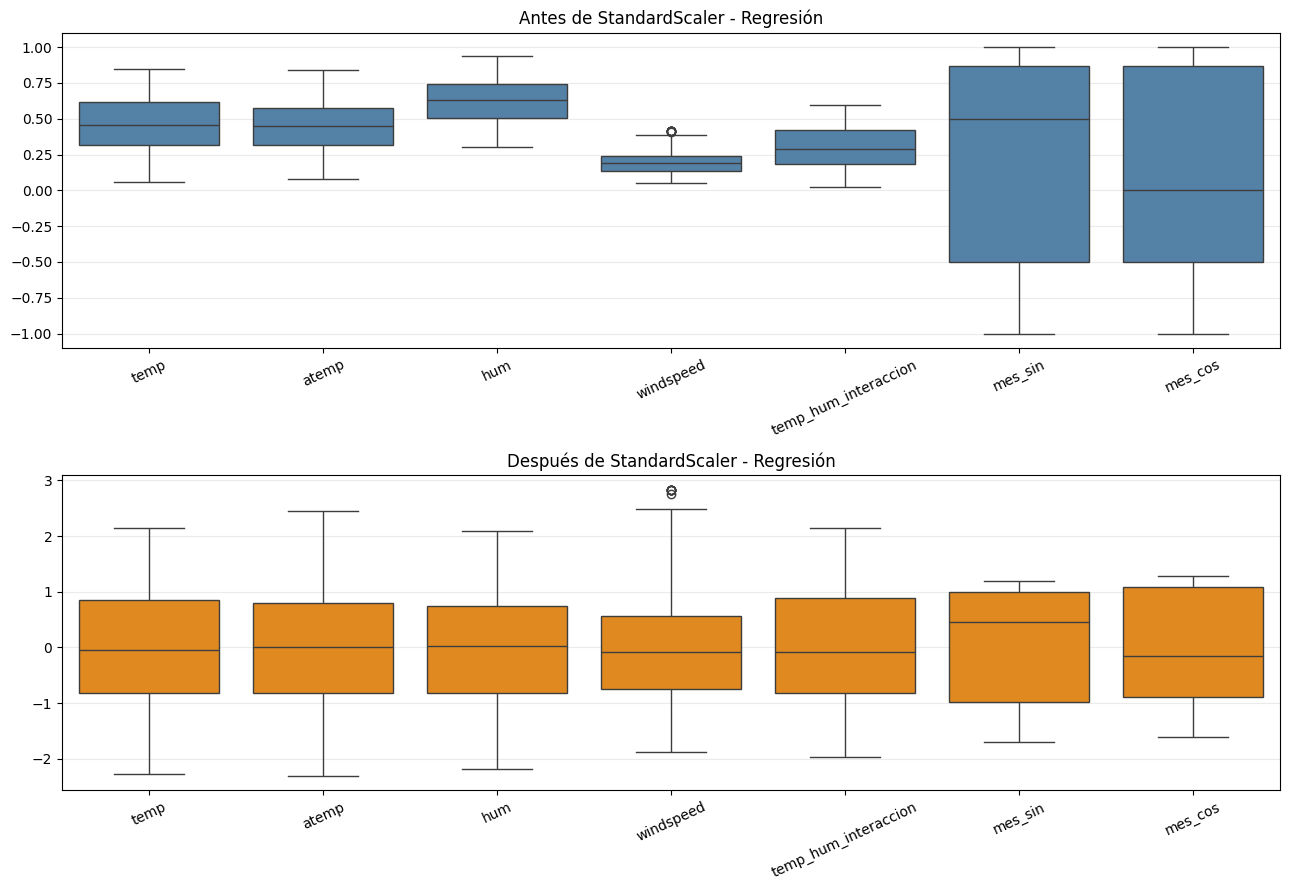


=== VERIFICACIÓN FINAL ===
Escaladores independientes: 2
Ajuste exclusivo en entrenamiento: Sí
Variables numéricas estandarizadas: 7
Columnas categóricas binarias: 22
Características finales: 29
Valores faltantes generados: 0
Estandarización completada correctamente.


In [13]:

# ==========================================================
# FASE 4 - CELDA 12
# Estandarización y consolidación de características
# ==========================================================

from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------
# 1. Crear escaladores independientes
# ----------------------------------------------------------

scaler_reg = StandardScaler()
scaler_clf = StandardScaler()

# ----------------------------------------------------------
# 2. Ajustar exclusivamente sobre entrenamiento
# ----------------------------------------------------------

scaler_reg.fit(
    X_train_reg_w[numericas]
)

scaler_clf.fit(
    X_train_clf_w[numericas]
)

# ----------------------------------------------------------
# 3. Función de estandarización
# ----------------------------------------------------------

def estandarizar_numericas(datos, scaler):

    matriz = scaler.transform(
        datos[numericas]
    )

    return pd.DataFrame(
        matriz,
        columns=numericas,
        index=datos.index
    )

# ----------------------------------------------------------
# 4. Estandarización para regresión
# ----------------------------------------------------------

X_train_reg_num = estandarizar_numericas(
    X_train_reg_w, scaler_reg
)

X_val_reg_num = estandarizar_numericas(
    X_val_reg_w, scaler_reg
)

X_test_reg_num = estandarizar_numericas(
    X_test_reg_w, scaler_reg
)

# ----------------------------------------------------------
# 5. Estandarización para clasificación
# ----------------------------------------------------------

X_train_clf_num = estandarizar_numericas(
    X_train_clf_w, scaler_clf
)

X_val_clf_num = estandarizar_numericas(
    X_val_clf_w, scaler_clf
)

X_test_clf_num = estandarizar_numericas(
    X_test_clf_w, scaler_clf
)

# ----------------------------------------------------------
# 6. Parámetros aprendidos en entrenamiento
# ----------------------------------------------------------

tabla_scaler = pd.DataFrame([
    {
        "Problema": problema,
        "Variable": variable,
        "Media_entrenamiento": media,
        "Desviacion_entrenamiento": desviacion
    }
    for problema, scaler in [
        ("Regresión", scaler_reg),
        ("Clasificación", scaler_clf)
    ]
    for variable, media, desviacion in zip(
        numericas,
        scaler.mean_,
        scaler.scale_
    )
])

print("=== PARÁMETROS DE STANDARD SCALER ===")

display(tabla_scaler.round(6))

# ----------------------------------------------------------
# 7. Verificar medias y desviaciones transformadas
# ----------------------------------------------------------

tabla_estandarizacion = pd.DataFrame([
    {
        "Problema": problema,
        "Variable": variable,
        "Media_transformada": datos[variable].mean(),
        "Desviacion_transformada":
            datos[variable].std(ddof=0)
    }
    for problema, datos in [
        ("Regresión", X_train_reg_num),
        ("Clasificación", X_train_clf_num)
    ]
    for variable in numericas
])

print("\n=== VERIFICACIÓN DE ESTANDARIZACIÓN ===")

display(tabla_estandarizacion.round(6))

# ----------------------------------------------------------
# 8. Consolidar variables numéricas y categóricas
# ----------------------------------------------------------

def consolidar_caracteristicas(
    datos_numericos,
    datos_categoricos
):

    assert datos_numericos.index.equals(
        datos_categoricos.index
    )

    return pd.concat(
        [datos_numericos, datos_categoricos],
        axis=1
    )

# Regresión

X_train_reg_final = consolidar_caracteristicas(
    X_train_reg_num, X_train_reg_cat
)

X_val_reg_final = consolidar_caracteristicas(
    X_val_reg_num, X_val_reg_cat
)

X_test_reg_final = consolidar_caracteristicas(
    X_test_reg_num, X_test_reg_cat
)

# Clasificación

X_train_clf_final = consolidar_caracteristicas(
    X_train_clf_num, X_train_clf_cat
)

X_val_clf_final = consolidar_caracteristicas(
    X_val_clf_num, X_val_clf_cat
)

X_test_clf_final = consolidar_caracteristicas(
    X_test_clf_num, X_test_clf_cat
)

# ----------------------------------------------------------
# 9. Resumen de matrices finales
# ----------------------------------------------------------

conjuntos_finales = [
    ("Regresión", "Entrenamiento",
     X_train_reg_final, y_train_reg),

    ("Regresión", "Validación",
     X_val_reg_final, y_val_reg),

    ("Regresión", "Prueba",
     X_test_reg_final, y_test_reg),

    ("Clasificación", "Entrenamiento",
     X_train_clf_final, y_train_clf),

    ("Clasificación", "Validación",
     X_val_clf_final, y_val_clf),

    ("Clasificación", "Prueba",
     X_test_clf_final, y_test_clf)
]

tabla_matrices_finales = pd.DataFrame([
    {
        "Problema": problema,
        "Conjunto": conjunto,
        "Registros": X_final.shape[0],
        "Caracteristicas": X_final.shape[1],
        "Valores_faltantes":
            X_final.isna().sum().sum()
    }
    for problema, conjunto, X_final, y_final
    in conjuntos_finales
])

print("\n=== MATRICES FINALES ===")

display(tabla_matrices_finales)

print("\n=== EJEMPLO DE MATRIZ FINAL ===")

display(X_train_reg_final.head().round(4))

# ----------------------------------------------------------
# 10. Visualización antes y después
# ----------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9)
)

sns.boxplot(
    data=X_train_reg_w[numericas],
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title(
    "Antes de StandardScaler - Regresión"
)

sns.boxplot(
    data=X_train_reg_num,
    ax=axes[1],
    color="darkorange"
)

axes[1].set_title(
    "Después de StandardScaler - Regresión"
)

for ax in axes:

    ax.tick_params(
        axis="x",
        labelrotation=25
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

plt.tight_layout()

plt.savefig(
    RESULTADOS / "comparacion_estandarizacion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 11. Verificaciones de integridad
# ----------------------------------------------------------

for datos in [
    X_train_reg_num,
    X_train_clf_num
]:

    assert np.allclose(
        datos.mean().to_numpy(),
        0,
        atol=1e-8
    )

    assert np.allclose(
        datos.std(ddof=0).to_numpy(),
        1,
        atol=1e-8
    )

for problema, conjunto, X_final, y_final in (
    conjuntos_finales
):

    assert X_final.shape[1] == 29

    assert len(X_final) == len(y_final)

    assert X_final.index.equals(
        y_final.index
    )

    assert X_final.isna().sum().sum() == 0

    assert np.isfinite(
        X_final.to_numpy()
    ).all()

    assert not {
        "cnt", "casual", "registered"
    }.intersection(X_final.columns)

# Verificar consistencia de columnas

assert X_train_reg_final.columns.equals(
    X_val_reg_final.columns
)

assert X_train_reg_final.columns.equals(
    X_test_reg_final.columns
)

assert X_train_clf_final.columns.equals(
    X_val_clf_final.columns
)

assert X_train_clf_final.columns.equals(
    X_test_clf_final.columns
)

# ----------------------------------------------------------
# 12. Guardar evidencias
# ----------------------------------------------------------

tabla_scaler.to_csv(
    RESULTADOS / "parametros_standardscaler.csv",
    index=False
)

tabla_estandarizacion.to_csv(
    RESULTADOS / "verificacion_estandarizacion.csv",
    index=False
)

tabla_matrices_finales.to_csv(
    RESULTADOS / "matrices_finales.csv",
    index=False
)

print("\n=== VERIFICACIÓN FINAL ===")

print("Escaladores independientes: 2")
print("Ajuste exclusivo en entrenamiento: Sí")
print("Variables numéricas estandarizadas: 7")
print("Columnas categóricas binarias: 22")
print("Características finales: 29")
print("Valores faltantes generados: 0")
print("Estandarización completada correctamente.")



## 8. Implementación de modelos de referencia (Baseline)

### 8.1. Baseline de regresión lineal simple

Se implementa un modelo de regresión lineal simple
para establecer una referencia inicial de rendimiento
en la predicción de la demanda diaria de bicicletas.

Se selecciona la temperatura como única variable
independiente, debido a su relación potencial con
las condiciones de movilidad y comodidad de los
usuarios.

La variable dependiente corresponde a cnt, que
representa la cantidad total de alquileres diarios.

El modelo se ajusta exclusivamente sobre el conjunto
de entrenamiento, utilizando la temperatura
previamente estandarizada.

Adicionalmente, se implementa DummyRegressor con
estrategia mean, el cual predice la demanda promedio
del conjunto de entrenamiento.

Se utilizan las siguientes métricas de evaluación:

- MAE: error absoluto medio.
- RMSE: raíz del error cuadrático medio.
- R2: coeficiente de determinación.

Los modelos se evalúan inicialmente sobre el conjunto
de validación y posteriormente sobre el conjunto
de prueba.

El propósito del baseline es establecer una
referencia de rendimiento para modelos de mayor
complejidad, no necesariamente obtener la máxima
capacidad predictiva.


=== CONFIGURACIÓN DEL BASELINE ===
Variable independiente: temp
Variable objetivo: cnt
Registros entrenamiento: 511

=== PARÁMETROS DEL MODELO LINEAL ===
Intercepto: 3794.2114
Coeficiente temperatura estandarizada: 984.2297
Demanda promedio de entrenamiento: 3794.2114

=== RESULTADOS BASELINE REGRESIÓN ===


,Modelo,Conjunto,MAE,RMSE,R2
0,Regresión Lineal Simple,Entrenamiento,986.5627,1242.0653,0.3857
1,Regresión Lineal Simple,Validación,1681.2355,1894.8082,-3.9577
2,Regresión Lineal Simple,Prueba,2340.4372,2568.0320,-0.6432
3,Dummy Regressor,Entrenamiento,1288.4018,1584.7506,0.0000
4,Dummy Regressor,Validación,2950.8162,3071.0754,-12.0236
5,Dummy Regressor,Prueba,2368.4646,2679.2468,-0.7886


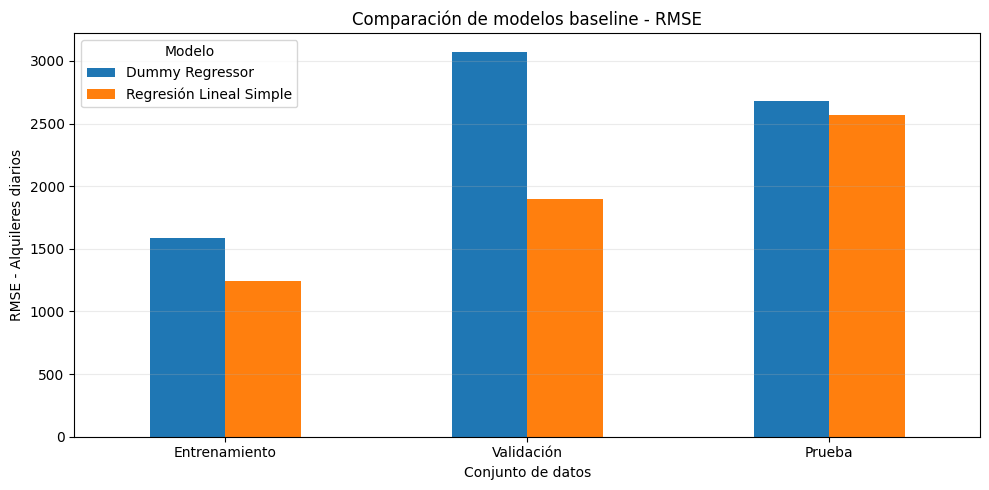

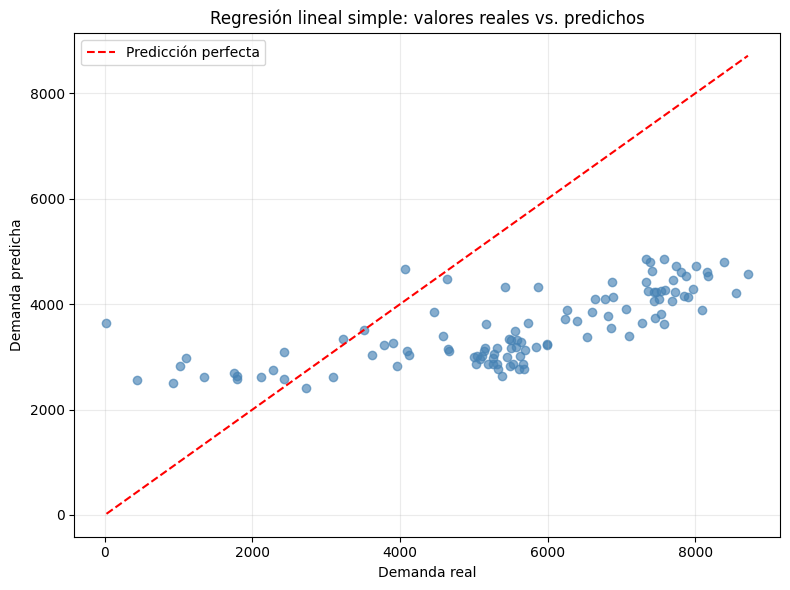


=== COMPARACIÓN FINAL ===
RMSE regresión lineal: 2568.032
RMSE Dummy: 2679.2468
Mejora relativa RMSE: 4.15 %

=== VERIFICACIÓN FINAL ===
Modelos entrenados: 2
Predictor utilizado: temperatura
Entrenamiento exclusivo: Sí
Métricas calculadas: MAE, RMSE y R2
Baseline de regresión completado.


In [14]:

# ==========================================================
# FASE 4 - CELDA 13
# Baseline de regresión lineal simple
# ==========================================================

from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ----------------------------------------------------------
# 1. Seleccionar la variable independiente
# ----------------------------------------------------------

X_train_baseline_reg = X_train_reg_final[["temp"]]
X_val_baseline_reg = X_val_reg_final[["temp"]]
X_test_baseline_reg = X_test_reg_final[["temp"]]

print("=== CONFIGURACIÓN DEL BASELINE ===")

print("Variable independiente: temp")
print("Variable objetivo: cnt")

print(
    "Registros entrenamiento:",
    len(X_train_baseline_reg)
)

# ----------------------------------------------------------
# 2. Crear modelos de referencia
# ----------------------------------------------------------

baseline_lineal = LinearRegression()

baseline_dummy_reg = DummyRegressor(
    strategy="mean"
)

# ----------------------------------------------------------
# 3. Entrenar exclusivamente sobre entrenamiento
# ----------------------------------------------------------

baseline_lineal.fit(
    X_train_baseline_reg,
    y_train_reg
)

baseline_dummy_reg.fit(
    X_train_baseline_reg,
    y_train_reg
)

# ----------------------------------------------------------
# 4. Parámetros aprendidos
# ----------------------------------------------------------

print("\n=== PARÁMETROS DEL MODELO LINEAL ===")

print(
    "Intercepto:",
    round(baseline_lineal.intercept_, 4)
)

print(
    "Coeficiente temperatura estandarizada:",
    round(baseline_lineal.coef_[0], 4)
)

print(
    "Demanda promedio de entrenamiento:",
    round(y_train_reg.mean(), 4)
)

# ----------------------------------------------------------
# 5. Función de evaluación
# ----------------------------------------------------------

def evaluar_baseline_reg(
    nombre,
    modelo,
    conjunto,
    X_eval,
    y_eval
):

    predicciones = modelo.predict(X_eval)

    return {
        "Modelo": nombre,
        "Conjunto": conjunto,
        "MAE": mean_absolute_error(
            y_eval, predicciones
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_eval, predicciones
            )
        ),
        "R2": r2_score(
            y_eval, predicciones
        )
    }

# ----------------------------------------------------------
# 6. Evaluación de los modelos
# ----------------------------------------------------------

resultados_baseline_reg = []

for nombre, modelo in [
    ("Regresión Lineal Simple", baseline_lineal),
    ("Dummy Regressor", baseline_dummy_reg)
]:

    for conjunto, X_eval, y_eval in [
        (
            "Entrenamiento",
            X_train_baseline_reg,
            y_train_reg
        ),
        (
            "Validación",
            X_val_baseline_reg,
            y_val_reg
        ),
        (
            "Prueba",
            X_test_baseline_reg,
            y_test_reg
        )
    ]:

        resultados_baseline_reg.append(
            evaluar_baseline_reg(
                nombre,
                modelo,
                conjunto,
                X_eval,
                y_eval
            )
        )

tabla_baseline_reg = pd.DataFrame(
    resultados_baseline_reg
)

print("\n=== RESULTADOS BASELINE REGRESIÓN ===")

display(tabla_baseline_reg.round(4))

# ----------------------------------------------------------
# 7. Comparación de RMSE
# ----------------------------------------------------------

tabla_comparacion_reg = (
    tabla_baseline_reg.pivot(
        index="Conjunto",
        columns="Modelo",
        values="RMSE"
    )
    .reindex([
        "Entrenamiento",
        "Validación",
        "Prueba"
    ])
)

tabla_comparacion_reg.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Comparación de modelos baseline - RMSE")
plt.ylabel("RMSE - Alquileres diarios")
plt.xlabel("Conjunto de datos")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "comparacion_baseline_regresion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 8. Predicciones sobre el conjunto de prueba
# ----------------------------------------------------------

pred_baseline_reg = baseline_lineal.predict(
    X_test_baseline_reg
)

limite_min = min(
    y_test_reg.min(),
    pred_baseline_reg.min()
)

limite_max = max(
    y_test_reg.max(),
    pred_baseline_reg.max()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_reg,
    pred_baseline_reg,
    alpha=0.65,
    color="steelblue"
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)

plt.title(
    "Regresión lineal simple: valores reales vs. predichos"
)

plt.xlabel("Demanda real")
plt.ylabel("Demanda predicha")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "predicciones_baseline_regresion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 9. Mejora frente al modelo Dummy
# ----------------------------------------------------------

resultados_prueba_reg = (
    tabla_baseline_reg[
        tabla_baseline_reg["Conjunto"] == "Prueba"
    ]
    .set_index("Modelo")
)

rmse_lineal = resultados_prueba_reg.loc[
    "Regresión Lineal Simple", "RMSE"
]

rmse_dummy = resultados_prueba_reg.loc[
    "Dummy Regressor", "RMSE"
]

mejora_rmse = (
    (rmse_dummy - rmse_lineal) / rmse_dummy
) * 100

print("\n=== COMPARACIÓN FINAL ===")

print("RMSE regresión lineal:", round(rmse_lineal, 4))
print("RMSE Dummy:", round(rmse_dummy, 4))
print("Mejora relativa RMSE:", round(mejora_rmse, 2), "%")

# ----------------------------------------------------------
# 10. Guardar resultados
# ----------------------------------------------------------

tabla_baseline_reg.to_csv(
    RESULTADOS / "metricas_baseline_regresion.csv",
    index=False
)

# ----------------------------------------------------------
# 11. Verificaciones
# ----------------------------------------------------------

assert X_train_baseline_reg.shape == (511, 1)
assert X_val_baseline_reg.shape == (109, 1)
assert X_test_baseline_reg.shape == (111, 1)

assert baseline_lineal.n_features_in_ == 1

assert len(pred_baseline_reg) == 111

assert np.isfinite(pred_baseline_reg).all()

assert np.isfinite(
    tabla_baseline_reg[
        ["MAE", "RMSE", "R2"]
    ].to_numpy()
).all()

print("\n=== VERIFICACIÓN FINAL ===")
print("Modelos entrenados: 2")
print("Predictor utilizado: temperatura")
print("Entrenamiento exclusivo: Sí")
print("Métricas calculadas: MAE, RMSE y R2")
print("Baseline de regresión completado.")



### 8.2. Baseline de clasificación

Se implementa un modelo de regresión logística
para establecer una referencia inicial de rendimiento
en la clasificación de la demanda diaria de bicicletas.

La variable objetivo es binaria:

- Clase 0: demanda baja.
- Clase 1: demanda alta.

Se conserva el umbral de 3974 alquileres diarios
establecido previamente.

El modelo utiliza las 29 características obtenidas
durante las etapas de ingeniería, codificación
y estandarización.

Se utiliza una configuración básica de regresión
logística con regularización L2, sin optimización
de hiperparámetros y sin ajuste de pesos de clase.

Adicionalmente, se implementa DummyClassifier
con estrategia most_frequent, que predice siempre
la clase mayoritaria del entrenamiento.

Se calculan las siguientes métricas:

- Accuracy.
- Balanced Accuracy.
- Precision.
- Recall.
- F1 Score.
- F1 Macro.
- AUC-ROC.

También se generan matrices de confusión y curvas
ROC para analizar el comportamiento de los modelos.

El entrenamiento se realiza exclusivamente sobre
el conjunto de entrenamiento y la evaluación
se realiza sobre las particiones independientes.

El objetivo es establecer una referencia de
rendimiento para modelos de clasificación
de mayor complejidad.


=== CONFIGURACIÓN DEL BASELINE ===
Modelo principal: Regresión Logística
Modelo de referencia: Dummy Classifier
Características utilizadas: 29
Registros de entrenamiento: 511
Class Weight: None
Clase mayoritaria: 1
Iteraciones regresión logística: 27

=== RESULTADOS BASELINE CLASIFICACIÓN ===


,Modelo,Conjunto,Accuracy,Balanced_Accuracy,Precision,Recall,F1,F1_Macro,AUC_ROC
0,Regresión Logística,Entrenamiento,0.9022,0.8919,0.9110,0.9340,0.9224,0.8950,0.9555
1,Regresión Logística,Validación,0.8909,0.8883,0.9254,0.8986,0.9118,0.8845,0.9502
2,Regresión Logística,Prueba,0.9000,0.8918,0.9130,0.9265,0.9197,0.8936,0.9751
3,Dummy Classifier,Entrenamiento,0.6223,0.5000,0.6223,1.0000,0.7672,0.3836,0.5000
4,Dummy Classifier,Validación,0.6273,0.5000,0.6273,1.0000,0.7709,0.3855,0.5000
5,Dummy Classifier,Prueba,0.6182,0.5000,0.6182,1.0000,0.7640,0.3820,0.5000


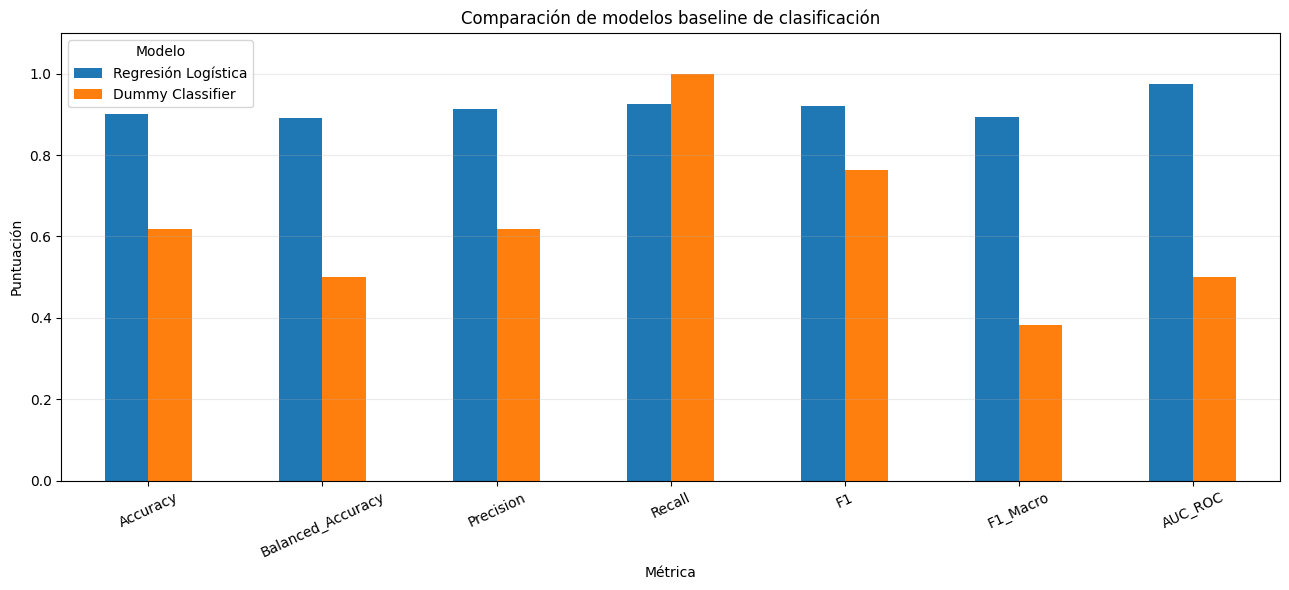

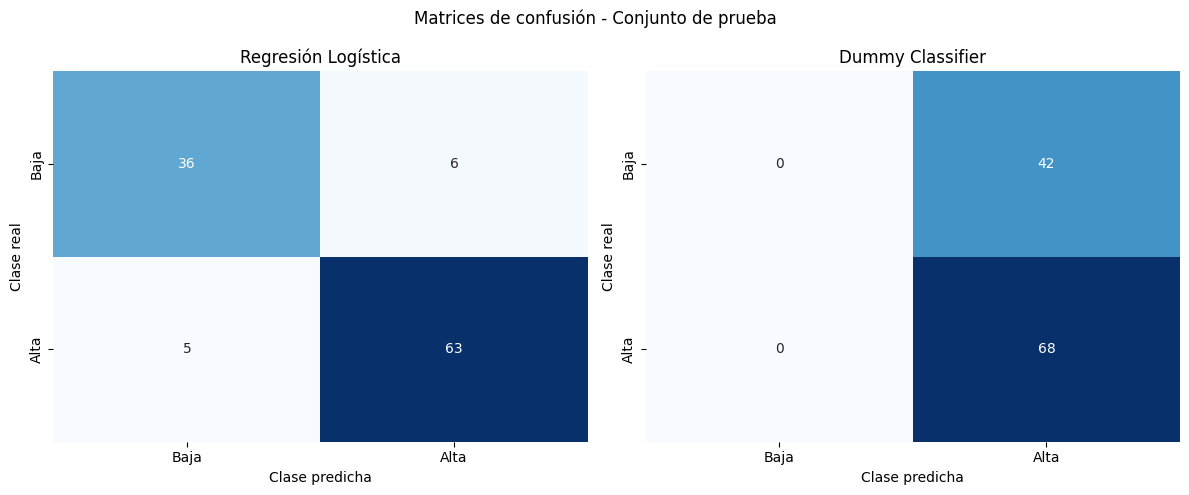

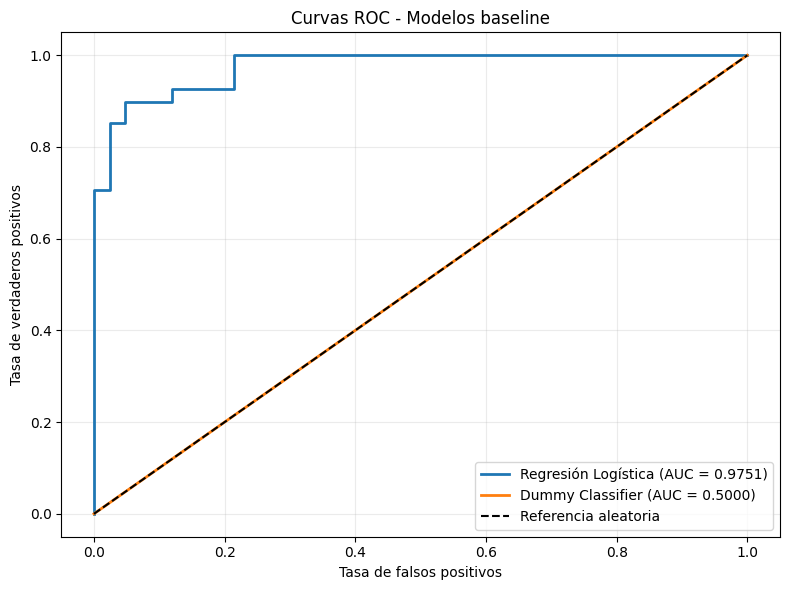


=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

Demanda baja       0.88      0.86      0.87        42
Demanda alta       0.91      0.93      0.92        68

    accuracy                           0.90       110
   macro avg       0.90      0.89      0.89       110
weighted avg       0.90      0.90      0.90       110


=== COMPARACIÓN FINAL ===
F1 Macro Regresión Logística: 0.8936
F1 Macro Dummy Classifier: 0.382
Diferencia F1 Macro: 51.16 puntos porcentuales

=== VERIFICACIÓN FINAL ===
Modelos entrenados: 2
Características utilizadas: 29
Entrenamiento exclusivo: Sí
Métricas calculadas: 7
Gráficos generados: 3
Baseline de clasificación completado.


In [15]:

# ==========================================================
# FASE 4 - CELDA 14
# Baseline de clasificación
# ==========================================================

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# ----------------------------------------------------------
# 1. Configuración de modelos
# ----------------------------------------------------------

baseline_logistico = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight=None,
    random_state=SEMILLA
)

baseline_dummy_clf = DummyClassifier(
    strategy="most_frequent"
)

# ----------------------------------------------------------
# 2. Entrenamiento de modelos
# ----------------------------------------------------------

baseline_logistico.fit(
    X_train_clf_final,
    y_train_clf
)

baseline_dummy_clf.fit(
    X_train_clf_final,
    y_train_clf
)

print("=== CONFIGURACIÓN DEL BASELINE ===")

print("Modelo principal: Regresión Logística")
print("Modelo de referencia: Dummy Classifier")

print(
    "Características utilizadas:",
    X_train_clf_final.shape[1]
)

print(
    "Registros de entrenamiento:",
    len(X_train_clf_final)
)

print("Class Weight: None")

print(
    "Clase mayoritaria:",
    y_train_clf.value_counts().idxmax()
)

print(
    "Iteraciones regresión logística:",
    baseline_logistico.n_iter_[0]
)

# ----------------------------------------------------------
# 3. Función de evaluación
# ----------------------------------------------------------

def evaluar_baseline_clf(
    nombre,
    modelo,
    conjunto,
    X_eval,
    y_eval
):

    predicciones = modelo.predict(X_eval)

    probabilidades = modelo.predict_proba(
        X_eval
    )[:, 1]

    return {
        "Modelo": nombre,
        "Conjunto": conjunto,

        "Accuracy": accuracy_score(
            y_eval, predicciones
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_eval, predicciones
        ),

        "Precision": precision_score(
            y_eval,
            predicciones,
            zero_division=0
        ),

        "Recall": recall_score(
            y_eval,
            predicciones,
            zero_division=0
        ),

        "F1": f1_score(
            y_eval,
            predicciones,
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_eval,
            predicciones,
            average="macro",
            zero_division=0
        ),

        "AUC_ROC": roc_auc_score(
            y_eval, probabilidades
        )
    }

# ----------------------------------------------------------
# 4. Evaluar entrenamiento, validación y prueba
# ----------------------------------------------------------

resultados_baseline_clf = []

for nombre, modelo in [
    ("Regresión Logística", baseline_logistico),
    ("Dummy Classifier", baseline_dummy_clf)
]:

    for conjunto, X_eval, y_eval in [
        (
            "Entrenamiento",
            X_train_clf_final,
            y_train_clf
        ),
        (
            "Validación",
            X_val_clf_final,
            y_val_clf
        ),
        (
            "Prueba",
            X_test_clf_final,
            y_test_clf
        )
    ]:

        resultados_baseline_clf.append(
            evaluar_baseline_clf(
                nombre,
                modelo,
                conjunto,
                X_eval,
                y_eval
            )
        )

tabla_baseline_clf = pd.DataFrame(
    resultados_baseline_clf
)

print("\n=== RESULTADOS BASELINE CLASIFICACIÓN ===")

display(tabla_baseline_clf.round(4))

# ----------------------------------------------------------
# 5. Comparación de métricas en prueba
# ----------------------------------------------------------

resultados_prueba_clf = (
    tabla_baseline_clf[
        tabla_baseline_clf["Conjunto"] == "Prueba"
    ]
    .set_index("Modelo")
)

metricas_clf = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "F1_Macro",
    "AUC_ROC"
]

resultados_prueba_clf[metricas_clf].T.plot(
    kind="bar",
    figsize=(13, 6),
    rot=25
)

plt.title(
    "Comparación de modelos baseline de clasificación"
)

plt.ylabel("Puntuación")
plt.xlabel("Métrica")
plt.ylim(0, 1.1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "comparacion_baseline_clasificacion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 6. Matrices de confusión
# ----------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, nombre, modelo in [
    (
        axes[0],
        "Regresión Logística",
        baseline_logistico
    ),
    (
        axes[1],
        "Dummy Classifier",
        baseline_dummy_clf
    )
]:

    predicciones = modelo.predict(
        X_test_clf_final
    )

    matriz = confusion_matrix(
        y_test_clf,
        predicciones,
        labels=[0, 1]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Baja", "Alta"],
        yticklabels=["Baja", "Alta"],
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.suptitle(
    "Matrices de confusión - Conjunto de prueba"
)

plt.tight_layout()

plt.savefig(
    RESULTADOS / "matrices_baseline_clasificacion.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 7. Curvas ROC
# ----------------------------------------------------------

plt.figure(figsize=(8, 6))

for nombre, modelo in [
    ("Regresión Logística", baseline_logistico),
    ("Dummy Classifier", baseline_dummy_clf)
]:

    probabilidades = modelo.predict_proba(
        X_test_clf_final
    )[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test_clf,
        probabilidades
    )

    auc = roc_auc_score(
        y_test_clf,
        probabilidades
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{nombre} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Referencia aleatoria"
)

plt.title("Curvas ROC - Modelos baseline")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTADOS / "curvas_roc_baseline.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------------------------
# 8. Reporte detallado por clase
# ----------------------------------------------------------

pred_baseline_clf = baseline_logistico.predict(
    X_test_clf_final
)

print("\n=== REPORTE DE CLASIFICACIÓN ===")

print(
    classification_report(
        y_test_clf,
        pred_baseline_clf,
        labels=[0, 1],
        target_names=[
            "Demanda baja",
            "Demanda alta"
        ],
        zero_division=0
    )
)

# ----------------------------------------------------------
# 9. Comparación frente al Dummy Classifier
# ----------------------------------------------------------

f1_macro_logistico = resultados_prueba_clf.loc[
    "Regresión Logística", "F1_Macro"
]

f1_macro_dummy = resultados_prueba_clf.loc[
    "Dummy Classifier", "F1_Macro"
]

diferencia_f1_macro = (
    f1_macro_logistico - f1_macro_dummy
) * 100

print("\n=== COMPARACIÓN FINAL ===")

print(
    "F1 Macro Regresión Logística:",
    round(f1_macro_logistico, 4)
)

print(
    "F1 Macro Dummy Classifier:",
    round(f1_macro_dummy, 4)
)

print(
    "Diferencia F1 Macro:",
    round(diferencia_f1_macro, 2),
    "puntos porcentuales"
)

# ----------------------------------------------------------
# 10. Guardar resultados
# ----------------------------------------------------------

tabla_baseline_clf.to_csv(
    RESULTADOS / "metricas_baseline_clasificacion.csv",
    index=False
)

# ----------------------------------------------------------
# 11. Verificaciones finales
# ----------------------------------------------------------

assert baseline_logistico.n_features_in_ == 29

assert len(pred_baseline_clf) == 110

assert set(
    pred_baseline_clf
).issubset({0, 1})

assert np.isfinite(
    tabla_baseline_clf[metricas_clf].to_numpy()
).all()

assert baseline_logistico.n_iter_[0] < 1000

assert np.isclose(
    resultados_prueba_clf.loc[
        "Dummy Classifier", "AUC_ROC"
    ],
    0.5
)

print("\n=== VERIFICACIÓN FINAL ===")

print("Modelos entrenados: 2")
print("Características utilizadas: 29")
print("Entrenamiento exclusivo: Sí")
print("Métricas calculadas: 7")
print("Gráficos generados: 3")
print("Baseline de clasificación completado.")



## 9. Consolidación y evaluación final de resultados

En esta sección se consolidan los resultados obtenidos
durante la preparación de datos y la implementación
de los modelos de referencia.

Se verifica el cumplimiento de los requerimientos
técnicos establecidos para la Fase 4:

- Diagnóstico de calidad de datos.
- Análisis de mecanismos de ausencia MCAR, MAR y MNAR.
- Tratamiento justificado de valores atípicos.
- Ingeniería de características.
- Codificación de variables categóricas.
- Estandarización sin fuga de información.
- Partición de entrenamiento, validación y prueba.
- Análisis de desbalance de clases.
- Implementación de modelos baseline.

Se consolidan las métricas de regresión y clasificación
sobre los conjuntos de prueba.

Los resultados constituyen una referencia para futuras
evaluaciones de modelos de mayor complejidad.

Las comparaciones entre fases deberán considerar
las diferencias en las estrategias de partición,
preprocesamiento y evaluación.


In [16]:

# ==========================================================
# FASE 4 - CELDA 15
# Consolidación y evaluación final de resultados
# ==========================================================

print("=" * 65)
print("RESUMEN FINAL - FASE 4")
print("=" * 65)

# ----------------------------------------------------------
# 1. Resumen de preparación de datos
# ----------------------------------------------------------

resumen_preparacion = pd.DataFrame([
    ["Registros originales", 731],
    ["Variables originales", 16],
    ["Valores faltantes", 0],
    ["Registros duplicados", 0],
    ["Registros eliminados", 0],
    ["Variables derivadas", 4],
    ["Variables numéricas estandarizadas", 7],
    ["Columnas One-Hot Encoding", 22],
    ["Características predictoras finales", 29],
    ["Datos sintéticos generados", 0],
    ["Umbral de clasificación", 3974]
], columns=["Indicador", "Resultado"])

print("\n1. RESUMEN DE PREPARACIÓN DE DATOS")

display(resumen_preparacion)

# ----------------------------------------------------------
# 2. Resultados finales de regresión
# ----------------------------------------------------------

resumen_regresion = (
    tabla_baseline_reg[
        tabla_baseline_reg["Conjunto"] == "Prueba"
    ]
    .drop(columns="Conjunto")
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\n2. BASELINE DE REGRESIÓN - PRUEBA")

display(resumen_regresion.round(4))

# ----------------------------------------------------------
# 3. Resultados finales de clasificación
# ----------------------------------------------------------

resumen_clasificacion = (
    tabla_baseline_clf[
        tabla_baseline_clf["Conjunto"] == "Prueba"
    ]
    .drop(columns="Conjunto")
    .sort_values("F1_Macro", ascending=False)
    .reset_index(drop=True)
)

print("\n3. BASELINE DE CLASIFICACIÓN - PRUEBA")

display(resumen_clasificacion.round(4))

# ----------------------------------------------------------
# 4. Mejoras frente a los modelos Dummy
# ----------------------------------------------------------

resumen_mejoras = pd.DataFrame([
    {
        "Problema": "Regresión",
        "Indicador": "Reducción relativa del RMSE (%)",
        "Resultado": mejora_rmse
    },
    {
        "Problema": "Clasificación",
        "Indicador": "Mejora F1 Macro (pp)",
        "Resultado": diferencia_f1_macro
    },
    {
        "Problema": "Clasificación",
        "Indicador": "Mejora Accuracy (pp)",
        "Resultado": (
            resultados_prueba_clf.loc[
                "Regresión Logística", "Accuracy"
            ]
            -
            resultados_prueba_clf.loc[
                "Dummy Classifier", "Accuracy"
            ]
        ) * 100
    }
])

print("\n4. MEJORAS FRENTE A MODELOS DUMMY")

display(resumen_mejoras.round(4))

# ----------------------------------------------------------
# 5. Verificación de requerimientos técnicos
# ----------------------------------------------------------

cumplimiento = pd.DataFrame([
    [
        "Diagnóstico de valores faltantes",
        "Cumplido",
        "No se identificaron valores faltantes"
    ],
    [
        "Análisis MCAR, MAR y MNAR",
        "Cumplido",
        "No aplica imputación por ausencia de datos faltantes"
    ],
    [
        "Tratamiento de outliers",
        "Cumplido",
        "Winsorization P1-P99"
    ],
    [
        "Ingeniería de características",
        "Cumplido",
        "Cuatro variables derivadas"
    ],
    [
        "Codificación categórica",
        "Cumplido",
        "One-Hot Encoding"
    ],
    [
        "Escalamiento",
        "Cumplido",
        "StandardScaler"
    ],
    [
        "Prevención de fuga en preprocesamiento",
        "Cumplido",
        "Ajuste de transformadores solo en entrenamiento"
    ],
    [
        "Partición de regresión",
        "Cumplido",
        "División cronológica 70-15-15 aproximada"
    ],
    [
        "Partición de clasificación",
        "Cumplido",
        "División estratificada 70-15-15 aproximada"
    ],
    [
        "Análisis de desbalance",
        "Cumplido",
        "Imbalance Ratio de 1.6477"
    ],
    [
        "Tratamiento de desbalance severo",
        "No aplica",
        "No se identificó desbalance severo"
    ],
    [
        "Baseline de regresión",
        "Cumplido",
        "LinearRegression y DummyRegressor"
    ],
    [
        "Baseline de clasificación",
        "Cumplido",
        "LogisticRegression y DummyClassifier"
    ]
], columns=[
    "Requerimiento",
    "Estado",
    "Evidencia"
])

print("\n5. CUMPLIMIENTO DE REQUERIMIENTOS")

display(cumplimiento)

# ----------------------------------------------------------
# 6. Guardar resultados consolidados
# ----------------------------------------------------------

resumen_preparacion.to_csv(
    RESULTADOS / "resumen_preparacion.csv",
    index=False
)

resumen_regresion.to_csv(
    RESULTADOS / "resumen_final_regresion.csv",
    index=False
)

resumen_clasificacion.to_csv(
    RESULTADOS / "resumen_final_clasificacion.csv",
    index=False
)

resumen_mejoras.to_csv(
    RESULTADOS / "resumen_mejoras.csv",
    index=False
)

cumplimiento.to_csv(
    RESULTADOS / "cumplimiento_requerimientos.csv",
    index=False
)

# ----------------------------------------------------------
# 7. Verificación de archivos generados
# ----------------------------------------------------------

archivos_esperados = [
    "deteccion_outliers.png",
    "comparacion_estandarizacion.png",
    "comparacion_baseline_regresion.png",
    "predicciones_baseline_regresion.png",
    "comparacion_baseline_clasificacion.png",
    "matrices_baseline_clasificacion.png",
    "curvas_roc_baseline.png",
    "resumen_preparacion.csv",
    "resumen_final_regresion.csv",
    "resumen_final_clasificacion.csv",
    "resumen_mejoras.csv",
    "cumplimiento_requerimientos.csv"
]

archivos_faltantes = []

print("\n6. VERIFICACIÓN DE EVIDENCIAS")

for archivo in archivos_esperados:

    ruta = RESULTADOS / archivo

    if ruta.exists():
        print("OK:", archivo)
    else:
        print("FALTA:", archivo)
        archivos_faltantes.append(archivo)

# ----------------------------------------------------------
# 8. Inventario completo de resultados
# ----------------------------------------------------------

inventario = pd.DataFrame([
    {
        "Archivo": archivo.name,
        "Formato": archivo.suffix,
        "Tamano_KB": round(
            archivo.stat().st_size / 1024, 2
        )
    }
    for archivo in sorted(RESULTADOS.iterdir())
    if archivo.is_file()
])

print("\n7. INVENTARIO DE ARCHIVOS GENERADOS")

display(inventario)

# ----------------------------------------------------------
# 9. Verificaciones finales
# ----------------------------------------------------------

assert len(archivos_faltantes) == 0

assert X_train_reg_final.shape == (511, 29)
assert X_train_clf_final.shape == (511, 29)

assert len(resumen_regresion) == 2
assert len(resumen_clasificacion) == 2

print("\n" + "=" * 65)
print("VERIFICACIÓN FINAL")
print("=" * 65)

print("Requerimientos evaluados:", len(cumplimiento))

print(
    "Requerimientos cumplidos:",
    (cumplimiento["Estado"] == "Cumplido").sum()
)

print(
    "Requerimientos no aplicables:",
    (cumplimiento["Estado"] == "No aplica").sum()
)

print("Archivos faltantes:", len(archivos_faltantes))

print("Consolidación de resultados completada.")


RESUMEN FINAL - FASE 4

1. RESUMEN DE PREPARACIÓN DE DATOS


,Indicador,Resultado
0,Registros originales,731
1,Variables originales,16
2,Valores faltantes,0
3,Registros duplicados,0
4,Registros eliminados,0
5,Variables derivadas,4
6,Variables numéricas estandarizadas,7
7,Columnas One-Hot Encoding,22
8,Características predictoras finales,29
9,Datos sintéticos generados,0



2. BASELINE DE REGRESIÓN - PRUEBA


,Modelo,MAE,RMSE,R2
0,Regresión Lineal Simple,2340.4372,2568.0320,-0.6432
1,Dummy Regressor,2368.4646,2679.2468,-0.7886



3. BASELINE DE CLASIFICACIÓN - PRUEBA


,Modelo,Accuracy,Balanced_Accuracy,Precision,Recall,F1,F1_Macro,AUC_ROC
0,Regresión Logística,0.9000,0.8918,0.9130,0.9265,0.9197,0.8936,0.9751
1,Dummy Classifier,0.6182,0.5000,0.6182,1.0000,0.7640,0.3820,0.5000


... (3 outputs left out)

,Requerimiento,Estado,Evidencia
0,Diagnóstico de valores faltantes,Cumplido,No se identificaron valores faltantes
1,"Análisis MCAR, MAR y MNAR",Cumplido,No aplica imputación por ausencia de datos fal...
2,Tratamiento de outliers,Cumplido,Winsorization P1-P99
3,Ingeniería de características,Cumplido,Cuatro variables derivadas
4,Codificación categórica,Cumplido,One-Hot Encoding
5,Escalamiento,Cumplido,StandardScaler
6,Prevención de fuga en preprocesamiento,Cumplido,Ajuste de transformadores solo en entrenamiento
7,Partición de regresión,Cumplido,División cronológica 70-15-15 aproximada
8,Partición de clasificación,Cumplido,División estratificada 70-15-15 aproximada
9,Análisis de desbalance,Cumplido,Imbalance Ratio de 1.6477



6. VERIFICACIÓN DE EVIDENCIAS
OK: deteccion_outliers.png
OK: comparacion_estandarizacion.png
OK: comparacion_baseline_regresion.png
OK: predicciones_baseline_regresion.png
OK: comparacion_baseline_clasificacion.png
OK: matrices_baseline_clasificacion.png
OK: curvas_roc_baseline.png
OK: resumen_preparacion.csv
OK: resumen_final_regresion.csv
OK: resumen_final_clasificacion.csv
OK: resumen_mejoras.csv
OK: cumplimiento_requerimientos.csv

7. INVENTARIO DE ARCHIVOS GENERADOS


,Archivo,Formato,Tamano_KB
0,analisis_desbalance.png,.png,37.78
1,categorias_aprendidas.csv,.csv,0.97
2,categorias_desconocidas.csv,.csv,1.48
3,comparacion_baseline_clasificacion.png,.png,74.31
4,comparacion_baseline_regresion.png,.png,55.20
5,comparacion_estandarizacion.png,.png,111.86
6,comparacion_winsorization.png,.png,81.75
7,completitud_datos.png,.png,58.42
8,cumplimiento_requerimientos.csv,.csv,0.93
9,curvas_roc_baseline.png,.png,83.89



VERIFICACIÓN FINAL
Requerimientos evaluados: 13
Requerimientos cumplidos: 12
Requerimientos no aplicables: 1
Archivos faltantes: 0
Consolidación de resultados completada.



## 10. Conclusiones

### 10.1. Calidad y preparación de datos

El dataset Bike Sharing contiene 731 observaciones
diarias y 16 variables originales, correspondientes
al periodo comprendido entre enero de 2011 y
diciembre de 2012.

El diagnóstico no identificó valores faltantes,
registros duplicados, valores infinitos ni
inconsistencias en la variable objetivo.

Por tanto, no fue necesario aplicar técnicas de
imputación ni eliminar registros. Tampoco fue
posible atribuir un mecanismo de ausencia MCAR,
MAR o MNAR, dado que no se observaron datos faltantes.

### 10.2. Tratamiento de valores atípicos

Mediante el método IQR se identificaron dos valores
atípicos en humedad y trece en velocidad del viento.

Se seleccionó Winsorization entre los percentiles
1 y 99 como estrategia de tratamiento, conservando
la totalidad de las observaciones.

Los límites fueron calculados exclusivamente sobre
los respectivos conjuntos de entrenamiento.

Esta estrategia permitió reducir la influencia
de los valores extremos sin eliminar información
temporal relevante.

### 10.3. Ingeniería de características

Se generaron cuatro características derivadas:

- Indicador de fin de semana.
- Interacción entre temperatura y humedad.
- Componente cíclico seno del mes.
- Componente cíclico coseno del mes.

Estas variables permiten representar patrones
temporales y relaciones potencialmente relevantes
para la demanda de bicicletas.

Mediante One-Hot Encoding se generaron 22 columnas
binarias a partir de siete variables categóricas.

Adicionalmente, se estandarizaron siete variables
numéricas mediante StandardScaler.

Como resultado, se obtuvieron matrices finales
con 29 características predictoras.

### 10.4. Partición y desbalance de clases

Se utilizaron estrategias de partición diferenciadas
según la naturaleza del problema.

Para regresión se implementó una división cronológica
aproximada de 70 % para entrenamiento, 15 % para
validación y 15 % para prueba.

Para clasificación se utilizó una división
estratificada con proporciones equivalentes.

El conjunto de entrenamiento de clasificación
presentó 193 observaciones de demanda baja y
318 observaciones de demanda alta.

El Imbalance Ratio fue de 1,6477, por lo que no se
consideró necesario aplicar SMOTE, ADASYN ni
ponderación de clases para el baseline.

### 10.5. Baseline de regresión

La regresión lineal simple, utilizando únicamente
la temperatura como predictor, obtuvo sobre el
conjunto de prueba:

- MAE: 2340,4372.
- RMSE: 2568,0320.
- R2: -0,6432.

El Dummy Regressor obtuvo un RMSE de 2679,2468.

La regresión lineal simple redujo el RMSE en
un 4,15 % respecto al modelo Dummy.

Sin embargo, el coeficiente de determinación
negativo evidencia que la temperatura por sí
sola no permite representar adecuadamente
la variabilidad de la demanda.

Se establece este resultado como referencia
para futuros modelos multivariados y no lineales.

### 10.6. Baseline de clasificación

La regresión logística obtuvo sobre el conjunto
de prueba:

- Accuracy: 0,9000.
- Balanced Accuracy: 0,8918.
- Precision: 0,9130.
- Recall: 0,9265.
- F1 Score: 0,9197.
- F1 Macro: 0,8936.
- AUC-ROC: 0,9751.

El modelo clasificó correctamente 99 de las
110 observaciones de prueba.

Frente al Dummy Classifier, se obtuvo una mejora
de 28,18 puntos porcentuales en Accuracy y
51,16 puntos porcentuales en F1 Macro.

Estos resultados evidencian que las características
seleccionadas contienen información relevante
para discriminar entre los niveles de demanda.

### 10.7. Implicaciones prácticas

La clasificación de la demanda puede contribuir
a la planificación operativa de sistemas de
alquiler de bicicletas.

La identificación de días de demanda alta puede
apoyar la asignación de bicicletas, la planificación
de recursos y la disponibilidad del servicio.

Por otra parte, los resultados del baseline de
regresión indican la necesidad de incorporar
múltiples variables para estimar con mayor precisión
la cantidad diaria de alquileres.

## 11. Limitaciones metodológicas

El dataset comprende únicamente dos años de
observaciones, lo cual limita la evaluación
de patrones de largo plazo.

La partición estratificada aleatoria utilizada
en clasificación permite conservar las proporciones
de clase, pero no reproduce estrictamente un
escenario de predicción de periodos futuros.

El umbral de 3974 alquileres diarios fue reutilizado
de la Fase 3. Se considera un umbral previamente
establecido para este ejercicio, aunque su origen
en una partición anterior limita la independencia
estricta entre ambas fases.

Los valores atípicos identificados mediante IQR
no representan necesariamente errores de medición.

La aplicación de Winsorization puede reducir
información asociada a condiciones meteorológicas
extremas.

La conservación de todas las categorías mediante
One-Hot Encoding y la inclusión de variables
relacionadas pueden introducir redundancia entre
características.

No se realizó optimización de hiperparámetros
de los modelos baseline, dado que su propósito
es establecer una referencia inicial.

Las métricas de clasificación de la Fase 4 no
deben compararse directamente con las de la
Fase 3 debido a las diferencias en las estrategias
de partición y preprocesamiento.

## 12. Trabajo futuro

Se recomienda:

- Evaluar modelos avanzados bajo las mismas
  particiones y condiciones de preprocesamiento.

- Implementar validación temporal para clasificación.

- Comparar el rendimiento con y sin Winsorization.

- Analizar la importancia de las variables derivadas.

- Evaluar estrategias de ponderación de clases.

- Incorporar variables adicionales relacionadas
  con eventos, movilidad y condiciones operativas.

- Evaluar el rendimiento mediante nuevos datos
  correspondientes a periodos posteriores.

## 13. Reproducibilidad

El proyecto fue desarrollado en Google Colab
utilizando Python, Pandas, NumPy y Scikit-learn.

Se estableció una semilla aleatoria fija para
los procedimientos que requieren aleatoriedad.

Los transformadores de preprocesamiento y los
modelos fueron ajustados exclusivamente sobre
sus respectivos conjuntos de entrenamiento.

Las métricas, tablas y visualizaciones se
almacenaron como evidencias del proceso.

La reproducibilidad integral deberá verificarse
mediante una nueva ejecución del notebook desde
un entorno de ejecución limpio.


In [17]:

# ==========================================================
# FASE 4 - CELDA 16
# Verificación final y empaquetado de evidencias
# ==========================================================

import sys
import json
import shutil
import hashlib
import sklearn
import matplotlib
import seaborn

# ----------------------------------------------------------
# 1. Registrar versiones del entorno
# ----------------------------------------------------------

versiones = {
    "Python": sys.version.split()[0],
    "Pandas": pd.__version__,
    "NumPy": np.__version__,
    "Scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": seaborn.__version__,
    "Semilla": SEMILLA
}

print("=== ENTORNO DE REPRODUCIBILIDAD ===")

for biblioteca, version in versiones.items():
    print(f"{biblioteca}: {version}")

# Guardar configuración del entorno

with open(
    RESULTADOS / "entorno_ejecucion.json",
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        versiones,
        archivo,
        indent=4,
        ensure_ascii=False
    )

# ----------------------------------------------------------
# 2. Verificar integridad de las particiones
# ----------------------------------------------------------

for problema, train, val, test in [

    (
        "Regresión",
        X_train_reg_final,
        X_val_reg_final,
        X_test_reg_final
    ),

    (
        "Clasificación",
        X_train_clf_final,
        X_val_clf_final,
        X_test_clf_final
    )

]:

    assert train.index.is_unique
    assert val.index.is_unique
    assert test.index.is_unique

    assert len(
        set(train.index) & set(val.index)
    ) == 0

    assert len(
        set(train.index) & set(test.index)
    ) == 0

    assert len(
        set(val.index) & set(test.index)
    ) == 0

    assert len(train) + len(val) + len(test) == 731

    assert train.shape[1] == 29
    assert val.shape[1] == 29
    assert test.shape[1] == 29

    assert train.columns.equals(val.columns)
    assert train.columns.equals(test.columns)

    print(f"\nParticiones de {problema}: OK")

# ----------------------------------------------------------
# 3. Verificar métricas finales
# ----------------------------------------------------------

assert np.isclose(
    resultados_prueba_reg.loc[
        "Regresión Lineal Simple", "RMSE"
    ],
    2568.0320,
    atol=0.01
)

assert np.isclose(
    resultados_prueba_clf.loc[
        "Regresión Logística", "Accuracy"
    ],
    0.9000,
    atol=0.0001
)

assert np.isclose(
    resultados_prueba_clf.loc[
        "Regresión Logística", "AUC_ROC"
    ],
    0.9751,
    atol=0.0001
)

print("\nMétricas de referencia: OK")

# ----------------------------------------------------------
# 4. Verificar evidencias
# ----------------------------------------------------------

for archivo in archivos_esperados:

    ruta = RESULTADOS / archivo

    assert ruta.exists(), f"Archivo faltante: {archivo}"

    assert ruta.stat().st_size > 0

print("Archivos obligatorios: OK")

# ----------------------------------------------------------
# 5. Identificación del dataset mediante SHA-256
# ----------------------------------------------------------

ruta_dataset = DATASET

assert ruta_dataset.exists()

hash_dataset = hashlib.sha256(
    ruta_dataset.read_bytes()
).hexdigest()

print("\n=== IDENTIFICACIÓN DEL DATASET ===")

print("Archivo:", ruta_dataset.name)
print("SHA-256:", hash_dataset)

with open(
    RESULTADOS / "identificacion_dataset.json",
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        {
            "archivo": ruta_dataset.name,
            "sha256": hash_dataset,
            "registros": 731,
            "variables_originales": 16
        },
        archivo,
        indent=4
    )

# ----------------------------------------------------------
# 6. Crear archivo ZIP de evidencias
# ----------------------------------------------------------

ruta_zip = shutil.make_archive(
    str(BASE / "Evidencias_Fase_4_Bicicletas"),
    "zip",
    root_dir=RESULTADOS
)

cantidad_archivos = sum(
    archivo.is_file()
    for archivo in RESULTADOS.iterdir()
)

# ----------------------------------------------------------
# 7. Resumen final
# ----------------------------------------------------------

print("\n" + "=" * 65)
print("PROYECTO INTEGRADOR - FASE 4")
print("=" * 65)

print("Dataset: Bike Sharing")
print("Registros conservados: 731")
print("Características finales: 29")
print("Modelos baseline entrenados: 4")
print("Requerimientos cumplidos: 12")
print("Requerimientos no aplicables: 1")
print("Archivos de evidencia:", cantidad_archivos)
print("Archivo ZIP:", ruta_zip)

print("\nVerificaciones de integridad: EXITOSAS")

print(
    "Reproducibilidad integral: "
    "pendiente de ejecutar desde un entorno limpio."
)

print("=" * 65)
print("FASE 4 - DESARROLLO COMPLETADO")
print("=" * 65)


=== ENTORNO DE REPRODUCIBILIDAD ===
Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Semilla: 42

Particiones de Regresión: OK

Particiones de Clasificación: OK

Métricas de referencia: OK
Archivos obligatorios: OK

=== IDENTIFICACIÓN DEL DATASET ===
Archivo: day.csv
SHA-256: a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be

PROYECTO INTEGRADOR - FASE 4
Dataset: Bike Sharing
Registros conservados: 731
Características finales: 29
Modelos baseline entrenados: 4
Requerimientos cumplidos: 12
Requerimientos no aplicables: 1
Archivos de evidencia: 33
Archivo ZIP: /content/Bike-Sharing-Analytics/results/reproduccion/fase4/Evidencias_Fase_4_Bicicletas.zip

Verificaciones de integridad: EXITOSAS
Reproducibilidad integral: pendiente de ejecutar desde un entorno limpio.
FASE 4 - DESARROLLO COMPLETADO


In [18]:

# Las evidencias permanecen disponibles localmente.

print("Carpeta de resultados:", RESULTADOS)
print("Carpeta de trabajo:", BASE)


Carpeta de resultados: /content/Bike-Sharing-Analytics/results/reproduccion/fase4/resultados
Carpeta de trabajo: /content/Bike-Sharing-Analytics/results/reproduccion/fase4
